# Automated Skin Disease Detection from Dermoscopic Images with Explainability Analysis
**Author:** Tashmika Pillay | **Supervisor:** Prof Serestina Viriri  
**Dataset:** HAM10000 | **University of KwaZulu-Natal**

---

## Research Phases
- **Phase 1** — Dataset and Preprocessing
- **Phase 2** — Architecture Design, Implementation and Evaluation
- **Phase 3** — Explainability Analysis (Grad-CAM, SHAP, Attention Maps)
- **Phase 4** — Ablation Study
- **Phase 5** — Few-Shot and Zero-Shot Learning (Exploratory)
- **Phase 6** — Extended Evaluation (confidence intervals, efficiency, multi-seed comparison, faithfulness of explanations, clinical interpretation)

## Environment Setup

In [1]:
!pip install -q grad-cam shap scikit-learn
print('Done.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Done.


In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models

from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, balanced_accuracy_score, cohen_kappa_score
)
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
warnings.filterwarnings('ignore')

# Larger text in every figure, so it is readable at paper size
plt.rcParams.update({'font.size': 13, 'axes.titlesize': 14, 'axes.labelsize': 13,
                     'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 12})

# Environment record: quote these in the paper
import torchvision
print('PyTorch', torch.__version__, '| torchvision', torchvision.__version__)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Device: cuda
PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
GPU: Tesla T4


In [3]:
# Run configuration
# The long experiments can be switched off here. Every training run they start is cached on Google Drive,
# so after a disconnect the finished runs are skipped when the notebook is run again.
RUN_ABLATION            = True    # Phase 4    ablation at 224 px (7 extra runs x up to 20 epochs)
RUN_MAIN_NO_TRANSFORMER = True    # Phase 2.5  train the main model again without its Transformer (448 px)
RUN_MULTISEED           = True    # Phase 6.2  4 models x 3 seeds at 224 px with an equal training budget (slow)
RUN_NOVEL_FS            = True    # Phase 5.1  train a 4-class model and test few-shot on 3 classes it has never seen
RUN_XAI_QUANT           = True    # Phase 6.6  deletion / insertion curves
N_BOOT                  = 2000    # bootstrap resamples for the confidence intervals
SEEDS                   = [42, 43, 44]

# Training pipeline of the main model and of the multi-seed comparison. Phase 4 varies one of these at a time.
MS_WEIGHTED_LOSS = False            # plain cross entropy (the weighted sampler already balances the classes)
MS_SAMPLER       = True             # class-balanced sampling
MS_IMAGES        = 'conservative'   # 'conservative' hair removal, 'aggressive' hair removal, or 'raw' images

---
# Phase 1 — Dataset and Preprocessing
**Covers:** HAM10000 download → exploratory data analysis → lesion-level split (70/15/15) → conservative hair removal → augmentation and class-balanced sampling

### 1.1 Load HAM10000 from Google Drive

**Steps before running:**
1. Upload `archive.zip` to your Google Drive (e.g. into `My Drive` root or a folder)
2. Update `ZIP_PATH` below if you put it in a subfolder
3. Run — Drive mounts, the zip extracts once

The zip contains everything: `HAM10000_images_part_1/`, `HAM10000_images_part_2/`, and `HAM10000_metadata.csv`.

In [4]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Set path to your archive.zip
ZIP_PATH  = '/content/drive/MyDrive/archive.zip'
DATA_ROOT = '/content/ham10000'

import os, subprocess

# Check zip file size on Drive
zip_size_gb = os.path.getsize(ZIP_PATH) / (1024**3)
print(f'archive.zip size on Drive: {zip_size_gb:.2f} GB')
if zip_size_gb < 2.0:
    print('WARNING: zip appears smaller than expected (~2.8 GB full dataset).')
    print('Re-upload archive.zip to Drive if the size is wrong.')

# Count existing images to decide whether to extract
def count_jpegs(folder):
    n = 0
    for _, _, files in os.walk(folder):
        n += sum(1 for f in files if f.endswith('.jpg'))
    return n

existing = count_jpegs(DATA_ROOT) if os.path.exists(DATA_ROOT) else 0
print(f'Images already extracted: {existing}')

if existing >= 10000:
    print('Full dataset already present, skipping extraction.')
else:
    # Remove partial extraction and re-extract cleanly using shell unzip (fast)
    if os.path.exists(DATA_ROOT):
        print('Removing incomplete extraction...')
        !rm -rf {DATA_ROOT}
    os.makedirs(DATA_ROOT, exist_ok=True)
    # Copy the zip off Drive first. Unzipping a 5 GB file straight from Drive often fails with "zipfile read error".
    LOCAL_ZIP = '/content/archive.zip'
    print(f'archive.zip on Drive: {os.path.getsize(ZIP_PATH):,} bytes (the complete file is 5,582,914,511 bytes)')
    print('Copying archive.zip from Drive to the Colab disk (a few minutes)...')
    !cp "{ZIP_PATH}" "{LOCAL_ZIP}"
    print('Extracting (this takes ~2-3 minutes)...')
    !unzip -q -o "{LOCAL_ZIP}" -d "{DATA_ROOT}"
    !rm -f "{LOCAL_ZIP}"
    final_count = count_jpegs(DATA_ROOT)
    print(f'Extraction complete. Images found: {final_count}')
    # Stop here rather than carry on with part of the dataset, which would silently change every result.
    assert final_count >= 10000, (f'Only {final_count} images extracted. Run this cell again. If it fails again, '
                                  'compare the byte count printed above: if it is smaller, re-upload archive.zip to Drive.')

Mounted at /content/drive
archive.zip size on Drive: 5.20 GB
Images already extracted: 0
archive.zip on Drive: 5,582,914,511 bytes (the complete file is 5,582,914,511 bytes)
Copying archive.zip from Drive to the Colab disk (a few minutes)...
Extracting (this takes ~2-3 minutes)...
Extraction complete. Images found: 20030


In [5]:
METADATA_CSV = os.path.join(DATA_ROOT, 'HAM10000_metadata.csv')
SAVE_DIR     = '/content/saved_models'
os.makedirs(SAVE_DIR, exist_ok=True)

# zip has both uppercase and lowercase folder names so scan all subfolder to build a single image_id -> filepath lookup (deduplicates automatically)
img_path_map = {}
for root, dirs, files in os.walk(DATA_ROOT):
    for f in files:
        if f.endswith('.jpg'):
            img_id = f[:-4]  # strip .jpg
            if img_id not in img_path_map:  # first match wins, avoids duplicates
                img_path_map[img_id] = os.path.join(root, f)

print(f'Unique images found: {len(img_path_map)}')  # should be 10,015

LABEL_MAP   = {'mel': 0, 'nv': 1, 'bkl': 2, 'bcc': 3, 'akiec': 4, 'vasc': 5, 'df': 6}
CLASS_NAMES = list(LABEL_MAP.keys())
NUM_CLASSES = len(LABEL_MAP)

meta = pd.read_csv(METADATA_CSV)
meta['label'] = meta['dx'].map(LABEL_MAP)
meta['path']  = meta['image_id'].map(img_path_map)
meta = meta.dropna(subset=['path']).reset_index(drop=True)

print(f'Matched metadata rows: {len(meta)}')
print(meta['dx'].value_counts())

Unique images found: 10015
Matched metadata rows: 10015
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


### 1.2 Exploratory Data Analysis

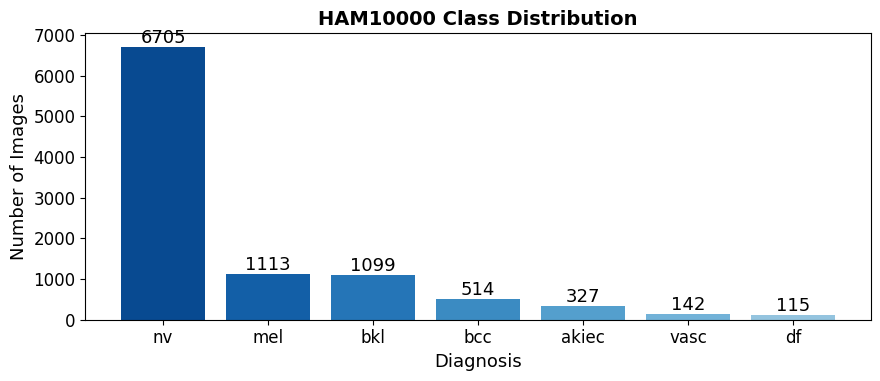

Imbalance ratio nv:df = 58.3:1


In [6]:
# Class distribution bar chart
counts = meta['dx'].value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(counts)))
bars = ax.bar(counts.index, counts.values, color=colors[::-1])
ax.bar_label(bars)
ax.set_title('HAM10000 Class Distribution', fontweight='bold')
ax.set_ylabel('Number of Images')
ax.set_xlabel('Diagnosis')
plt.tight_layout()
plt.savefig('/content/class_distribution.png', dpi=150)
plt.show()
print(f'Imbalance ratio nv:df = {counts["nv"]/counts["df"]:.1f}:1')

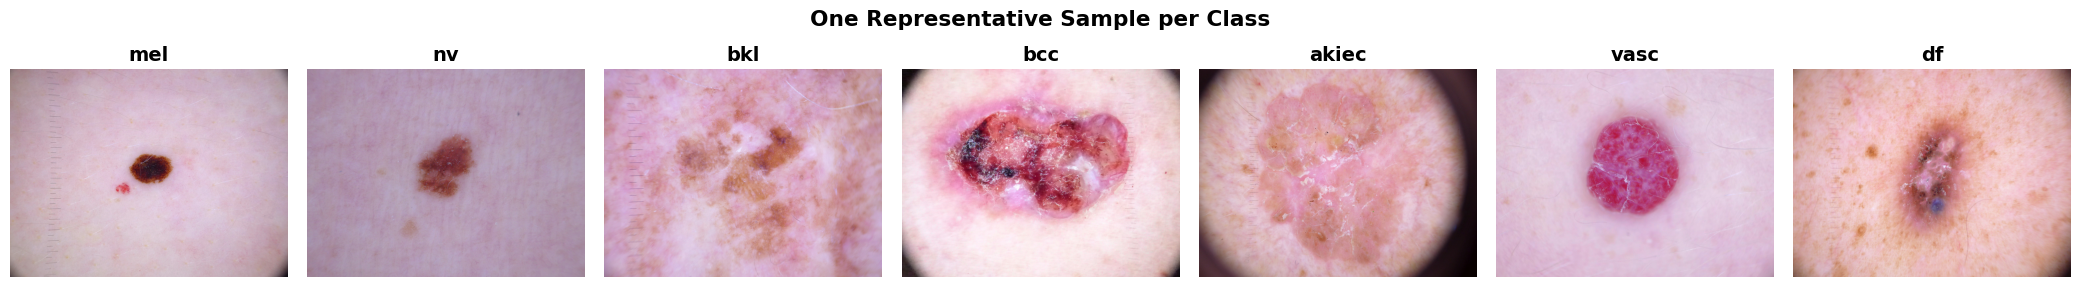

In [7]:
# Sample images from each class
fig, axes = plt.subplots(1, 7, figsize=(21, 3))
for ax, cls in zip(axes, CLASS_NAMES):
    sample_path = meta[meta['dx'] == cls]['path'].iloc[0]
    img = cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.set_title(cls, fontweight='bold'); ax.axis('off')
plt.suptitle('One Representative Sample per Class', fontweight='bold')
plt.tight_layout()
plt.savefig('/content/class_samples.png', dpi=150)
plt.show()

### 1.3 Lesion-Level Train / Validation / Test Split (70 / 15 / 15)

HAM10000 uses `lesion_id` as the patient-level grouping — multiple dermoscopic images can exist per lesion. Splitting on `lesion_id` ensures no lesion's images appear in more than one split, preventing data leakage.

In [8]:
# Split on lesion_id so no lesion's images leak across train/val/test.
unique_lesions = meta['lesion_id'].unique()
print(f'Unique lesions: {len(unique_lesions)} | Total images: {len(meta)}')

les_train, les_temp = train_test_split(unique_lesions, test_size=0.30, random_state=SEED)
les_val,   les_test = train_test_split(les_temp,       test_size=0.50, random_state=SEED)

train_df = meta[meta['lesion_id'].isin(les_train)].reset_index(drop=True)
val_df   = meta[meta['lesion_id'].isin(les_val)  ].reset_index(drop=True)
test_df  = meta[meta['lesion_id'].isin(les_test) ].reset_index(drop=True)

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')
print('Train class counts:')
print(train_df['dx'].value_counts())

Unique lesions: 7470 | Total images: 10015
Train: 6987 | Val: 1512 | Test: 1516
Train class counts:
dx
nv       4728
mel       775
bkl       734
bcc       355
akiec     235
vasc       85
df         75
Name: count, dtype: int64


### 1.4 Preprocessing — Hair Removal

A black-hat morphological transform highlights dark, thin structures. Only connected regions that are shaped like a hair (long, and thin or sparse inside their bounding box) are kept in the mask, and those pixels are filled by Telea inpainting. Images without hair are left unchanged.

The more aggressive variant that thresholds the black-hat response directly is kept only for the ablation in Phase 4, which shows that it removes lesion detail and lowers accuracy.

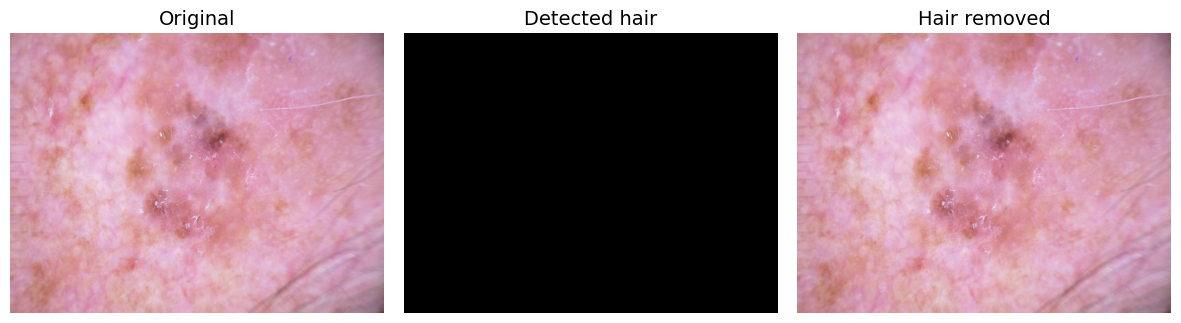

In [9]:
def hair_mask(img_bgr: np.ndarray, kernel_size: int = 11, threshold: int = 22, min_length: int = 35) -> np.ndarray:
    """Mask of hair pixels: dark, thin structures that are long, and thin or sparse inside their bounding box."""
    gray     = cv2.GaussianBlur(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), (3, 3), 0)
    kernel   = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    cand     = (blackhat > threshold).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(cand, connectivity=8)
    w, h, area = stats[:, cv2.CC_STAT_WIDTH], stats[:, cv2.CC_STAT_HEIGHT], stats[:, cv2.CC_STAT_AREA]
    length = np.maximum(w, h)
    fill   = area / np.maximum(w * h, 1)
    aspect = length / np.maximum(np.minimum(w, h), 1)
    keep   = (length >= min_length) & ((fill < 0.35) | (aspect >= 4))
    keep[0] = False                                   # label 0 is the background
    mask = (keep[labels] * 255).astype(np.uint8)
    return cv2.dilate(mask, np.ones((3, 3), np.uint8))


def remove_hair(img_bgr: np.ndarray) -> np.ndarray:
    """Conservative hair removal used throughout the project."""
    mask = hair_mask(img_bgr)
    if not mask.any():
        return img_bgr
    return cv2.inpaint(img_bgr, mask, inpaintRadius=3, flags=cv2.INPAINT_TELEA)


def aggressive_hair_mask(img_bgr: np.ndarray, kernel_size: int = 17, threshold: int = 10) -> np.ndarray:
    gray     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kernel   = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, mask  = cv2.threshold(blackhat, threshold, 255, cv2.THRESH_BINARY)
    return mask


def remove_hair_aggressive(img_bgr: np.ndarray) -> np.ndarray:
    """Plain black-hat threshold + inpainting. Used only as an ablation variant."""
    return cv2.inpaint(img_bgr, aggressive_hair_mask(img_bgr), inpaintRadius=3, flags=cv2.INPAINT_TELEA)


# Visualise original / detected hair / result
sample_path = train_df['path'].iloc[0]
orig = cv2.imread(sample_path)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB));              axes[0].set_title('Original')
axes[1].imshow(hair_mask(orig), cmap='gray');                       axes[1].set_title('Detected hair')
axes[2].imshow(cv2.cvtColor(remove_hair(orig), cv2.COLOR_BGR2RGB)); axes[2].set_title('Hair removed')
for a in axes: a.axis('off')
plt.tight_layout()
plt.savefig('/content/hair_removal_demo.png', dpi=150)
plt.show()

### 1.5 Datasets, Augmentation and Class-Balanced Sampling

In [10]:
IMG_SIZE   = 448
BATCH_SIZE = 16   # smaller batch needed for 448x448 resolution
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# Each preprocessing variant is written to disk once, so the DataLoader does not redo it on every batch.
IMAGE_DIRS  = {'conservative': '/content/ham10000_clean', 'aggressive': '/content/ham10000_aggressive'}
IMAGE_FUNCS = {'conservative': remove_hair, 'aggressive': remove_hair_aggressive}
IMAGE_COLS  = {'raw': 'path', 'conservative': 'clean_path', 'aggressive': 'aggr_path'}

def preprocess_all_images(meta, out_dir, fn):
    os.makedirs(out_dir, exist_ok=True)
    already_done = len([f for f in os.listdir(out_dir) if f.endswith('.jpg')])
    if already_done >= len(meta):
        print(f'All {already_done} images already preprocessed in {out_dir}, skipping.')
        return
    print(f'Preprocessing {len(meta)} images into {out_dir} (runs once)...')
    for n_done, (image_id, path) in enumerate(zip(meta['image_id'], meta['path']), 1):
        out_path = os.path.join(out_dir, image_id + '.jpg')
        if not os.path.exists(out_path):
            cv2.imwrite(out_path, fn(cv2.imread(path)))
        if n_done % 1000 == 0:
            print(f'  {n_done}/{len(meta)} done')
    print('Preprocessing complete.')

def image_column(kind):
    """Dataframe column holding the image paths of a preprocessing variant ('raw', 'conservative', 'aggressive').
    A variant is processed the first time it is asked for."""
    col = IMAGE_COLS[kind]
    if col not in meta.columns:
        preprocess_all_images(meta, IMAGE_DIRS[kind], IMAGE_FUNCS[kind])
        for df in (meta, train_df, val_df, test_df):
            df[col] = df['image_id'].apply(lambda x: os.path.join(IMAGE_DIRS[kind], x + '.jpg'))
    return col

image_column('conservative')      # the pipeline used for the main model


# Dataset (reads the images with conservative hair removal already applied)
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.15)),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


class HAM10000Dataset(Dataset):
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        img_bgr = cv2.imread(row['clean_path'])
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_pil = Image.fromarray(img_rgb)
        if self.transform:
            img_pil = self.transform(img_pil)
        return img_pil, int(row['label'])


# Rebuild splits to include clean_path
train_df = meta[meta['lesion_id'].isin(les_train)].reset_index(drop=True)
val_df   = meta[meta['lesion_id'].isin(les_val)  ].reset_index(drop=True)
test_df  = meta[meta['lesion_id'].isin(les_test) ].reset_index(drop=True)

# Inverse-frequency class weights: used by the class-balanced sampler (and by the weighted-loss ablation rows)
class_counts         = np.bincount(train_df['label'].values, minlength=NUM_CLASSES)
class_weights        = len(train_df) / (NUM_CLASSES * class_counts)
class_weights_tensor = torch.FloatTensor(class_weights).to(device)
print('Class weights:', {CLASS_NAMES[i]: f'{class_weights[i]:.2f}' for i in range(NUM_CLASSES)})

train_ds = HAM10000Dataset(train_df, transform=train_transform)
val_ds   = HAM10000Dataset(val_df,   transform=val_transform)
test_ds  = HAM10000Dataset(test_df,  transform=val_transform)

sample_weights = class_weights[train_df['label'].values]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f'Loaders ready — Train: {len(train_loader)} batches | Val: {len(val_loader)} | Test: {len(test_loader)}')

Preprocessing 10015 images into /content/ham10000_clean (runs once)...
  1000/10015 done
  2000/10015 done
  3000/10015 done
  4000/10015 done
  5000/10015 done
  6000/10015 done
  7000/10015 done
  8000/10015 done
  9000/10015 done
  10000/10015 done
Preprocessing complete.
Class weights: {'mel': '1.29', 'nv': '0.21', 'bkl': '1.36', 'bcc': '2.81', 'akiec': '4.25', 'vasc': '11.74', 'df': '13.31'}
Loaders ready — Train: 437 batches | Val: 95 | Test: 95


---
# Phase 2 — Architecture Design, Implementation and Evaluation
**Covers:**
- Proposed lightweight hybrid CNN-Transformer model (MobileNetV3-Small + compact Transformer encoder)
- Baseline models: EfficientNet-B3, ViT-B/16 (trained and compared under an equal budget in Phase 6.2)
- Training protocol (AdamW, CosineAnnealingLR, early stopping, class-balanced sampling)
- Evaluation: accuracy, balanced accuracy, macro F1, macro AUROC, Cohen's kappa

### 2.1 Proposed Model — Lightweight Hybrid CNN-Transformer

**Architecture:**
- **CNN Backbone:** MobileNetV3-Small feature extractor (ImageNet pretrained, ~0.9M params) → spatial feature map `(B, 576, 14, 14)` for a 448×448 input
- **Patch Tokenisation:** flatten spatial dims → linear projection to `embed_dim=384` → 196 patch tokens
- **[CLS] token + positional embedding**
- **Compact Transformer Encoder:** 4 layers, 4 heads, GELU, Pre-LayerNorm for training stability
- **Classification Head:** [CLS] token → Dropout → Linear(384 → 7)

In [11]:
class LightweightHybridModel(nn.Module):
    """
    Lightweight CNN-Transformer hybrid for dermoscopic classification.
    MobileNetV3-Small backbone → patch tokenisation → compact Transformer encoder.
    """
    def __init__(
        self,
        num_classes: int = 7,
        embed_dim: int = 384,
        num_heads: int = 4,
        num_transformer_layers: int = 4,
        dropout: float = 0.1,
        img_size: int = 224,
        pretrained: bool = True,      # False = random init (ablation)
        use_transformer: bool = True, # False = CNN only (ablation)
    ):
        super().__init__()
        self.use_transformer = use_transformer

        # CNN Backbone
        mobilenet = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None)
        self.cnn_backbone = mobilenet.features  # output: (B, 576, 7, 7) for 224×224
        cnn_channels = 576

        # Patch Tokenisation
        # eval() so this dummy pass does not overwrite BatchNorm running statistics
        mobilenet.features.eval()
        with torch.no_grad():
            _dummy = torch.zeros(1, 3, img_size, img_size)
            _feat  = mobilenet.features(_dummy)
            num_patches = _feat.shape[2] * _feat.shape[3]# MobileNetV3 downsamples 32×
        mobilenet.features.train()
        self.patch_proj = nn.Linear(cnn_channels, embed_dim)

        self.cls_token  = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed  = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed,  std=0.02)
        self.dropout_embed = nn.Dropout(dropout)

        # Compact Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout, activation='gelu',
            batch_first=True, norm_first=True,  # Pre-LN
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_transformer_layers)
        self.norm = nn.LayerNorm(embed_dim)

        # Classification Head
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(embed_dim, num_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # 1. CNN: extract local spatial features
        feat = self.cnn_backbone(x)                    # (B, 576, H, W)
        B, C, H, W = feat.shape

        # 2. Tokenise spatial features
        tokens = feat.flatten(2).transpose(1, 2)       # (B, H*W, 576)
        tokens = self.patch_proj(tokens)               # (B, H*W, embed_dim)

        if not self.use_transformer:
            # CNN-only ablation: mean-pool the projected tokens, same norm and head
            return self.head(self.norm(tokens.mean(1)))

        # 3. Prepend CLS token + positional encoding
        cls    = self.cls_token.expand(B, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1)       # (B, H*W+1, embed_dim)
        tokens = self.dropout_embed(tokens + self.pos_embed)

        # 4. Transformer: model global context across patch tokens
        tokens = self.transformer(tokens)
        tokens = self.norm(tokens)

        # 5. Classify from CLS token
        return self.head(tokens[:, 0])

    def get_attention_weights(self, x: torch.Tensor):
        """Extract per-layer attention weights for Phase 3 visualisation."""
        feat = self.cnn_backbone(x)
        B, C, H, W = feat.shape
        tokens = self.patch_proj(feat.flatten(2).transpose(1, 2))
        cls    = self.cls_token.expand(B, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos_embed

        attn_weights = []
        for layer in self.transformer.layers:
            src = layer.norm1(tokens) if layer.norm_first else tokens
            _, w = layer.self_attn(src, src, src, need_weights=True, average_attn_weights=False)
            attn_weights.append(w.detach().cpu())  # (B, num_heads, seq_len, seq_len)
            tokens = layer(tokens)
        return attn_weights, H, W


hybrid_model = LightweightHybridModel(num_classes=NUM_CLASSES, embed_dim=384, img_size=IMG_SIZE, dropout=0.3).to(device)

total     = sum(p.numel() for p in hybrid_model.parameters())
trainable = sum(p.numel() for p in hybrid_model.parameters() if p.requires_grad)
print(f'Total parameters    : {total:,}')
print(f'Trainable parameters: {trainable:,}')

# Sanity-check forward pass (eval mode, so the random noise does not leak into the BatchNorm running statistics)
hybrid_model.eval()
with torch.no_grad():
    out = hybrid_model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device))
hybrid_model.train()
print(f'Output shape: {out.shape}')  # (2, 7)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 181MB/s]


Total parameters    : 8,325,927
Trainable parameters: 8,325,927
Output shape: torch.Size([2, 7])


### 2.2 Baseline Models — EfficientNet-B3 and ViT-B/16

In [12]:
def build_efficientnet_b3(num_classes: int = 7) -> nn.Module:
    model = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.DEFAULT)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model

def build_vit_b16(num_classes: int = 7) -> nn.Module:
    model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
    model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    return model

# Parameter count comparison
for name, builder in [('EfficientNet-B3', build_efficientnet_b3), ('ViT-B/16', build_vit_b16)]:
    m = builder()
    print(f'{name}: {sum(p.numel() for p in m.parameters()):,} params')
print(f'Hybrid (ours): {total:,} params')

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 220MB/s]


EfficientNet-B3: 10,706,991 params
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 173MB/s]


ViT-B/16: 85,804,039 params
Hybrid (ours): 8,325,927 params


### 2.3 Training Protocol — AdamW + CosineAnnealingLR + Early Stopping

In [13]:
from torch.optim.lr_scheduler import CosineAnnealingLR


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += labels.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        logits = model(imgs)
        total_loss += criterion(logits, labels).item() * labels.size(0)
        probs  = torch.softmax(logits, dim=1)
        preds  = logits.argmax(1)
        correct += (preds == labels).sum().item()
        total   += labels.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
    return total_loss / total, correct / total, np.array(all_preds), np.array(all_labels), np.array(all_probs)


def train_model(model, model_name, train_loader, val_loader,
                num_epochs=20, lr=1e-4, weight_decay=1e-4, patience=5,
                class_weights=class_weights_tensor, save_dir=None):
    """class_weights=None trains with plain (unweighted) cross entropy.
    The default keeps the behaviour of the original runs."""
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs)

    best_val_loss = float('inf')
    no_improve    = 0
    history       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_path     = os.path.join(save_dir or SAVE_DIR, f'{model_name}_best.pth')
    os.makedirs(os.path.dirname(best_path), exist_ok=True)

    for epoch in range(1, num_epochs + 1):
        tr_loss, tr_acc     = train_one_epoch(model, train_loader, criterion, optimizer, device)
        vl_loss, vl_acc, *_ = evaluate(model, val_loader, criterion, device)
        scheduler.step()

        for key, val in zip(['train_loss', 'val_loss', 'train_acc', 'val_acc'],
                             [tr_loss, vl_loss, tr_acc, vl_acc]):
            history[key].append(val)

        print(f'[{model_name}] Epoch {epoch:3d}/{num_epochs} | '
              f'Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | '
              f'Val Loss: {vl_loss:.4f} Acc: {vl_acc:.4f}')

        if vl_loss < best_val_loss:
            best_val_loss = vl_loss; no_improve = 0
            torch.save(model.state_dict(), best_path)
        else:
            no_improve += 1
            if no_improve >= patience:
                history['stopped_epoch'] = epoch
                print(f'Early stopping at epoch {epoch}.')
                break

    history['best_epoch'] = int(np.argmin(history['val_loss'])) + 1
    model.load_state_dict(torch.load(best_path, map_location=device))
    print(f'Best model restored from {best_path}')
    return model, history


In [14]:
# ---------------------------------------------------------------------------
# Experiment runner (used by the ablation and the multi-seed comparison)
# ---------------------------------------------------------------------------
import json, time

RESULTS_JSON = '/content/drive/MyDrive/final_run_results.json'   # survives Colab disconnects


def load_results():
    if not os.path.exists(RESULTS_JSON):
        return {}
    with open(RESULTS_JSON) as f:      # an unreadable file raises here instead of being treated as empty
        return json.load(f)


def save_result(key, value):
    res = load_results()
    res[key] = value
    os.makedirs(os.path.dirname(RESULTS_JSON), exist_ok=True)
    tmp = RESULTS_JSON + '.tmp'        # write to a temp file first, so a crash mid-write cannot damage saved results
    with open(tmp, 'w') as f:
        json.dump(res, f, indent=1, default=float)
    os.replace(tmp, RESULTS_JSON)


def print_history(name, h):
    """Print a saved training history in the same form as the live training log."""
    for e in range(len(h['train_loss'])):
        print(f"[{name}] Epoch {e + 1:3d} | Train Loss: {h['train_loss'][e]:.4f} Acc: {h['train_acc'][e]:.4f} | "
              f"Val Loss: {h['val_loss'][e]:.4f} Acc: {h['val_acc'][e]:.4f}")
    if 'stopped_epoch' in h:
        print(f"Early stopping at epoch {h['stopped_epoch']}.")
    print(f"Best epoch: {h.get('best_epoch')}")


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


class HAMDataset(Dataset):
    """Same as HAM10000Dataset but the image column is selectable (see image_column)."""
    def __init__(self, df, transform=None, path_col='clean_path'):
        self.df, self.transform, self.path_col = df.reset_index(drop=True), transform, path_col
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.fromarray(cv2.cvtColor(cv2.imread(row[self.path_col]), cv2.COLOR_BGR2RGB))
        if self.transform:
            img = self.transform(img)
        return img, int(row['label'])


def build_loaders(img_size, use_sampler=True, images='conservative', seed=42, batch_size=BATCH_SIZE):
    """Same augmentation as the main training run (incl. random erasing)."""
    t_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
        transforms.RandomRotation(20),
        transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD),
        transforms.RandomErasing(p=0.3, scale=(0.02, 0.15)),
    ])
    v_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    ])
    col = image_column(images)
    tr_ds = HAMDataset(train_df, t_tf, col)
    vl_ds = HAMDataset(val_df,   v_tf, col)
    te_ds = HAMDataset(test_df,  v_tf, col)
    g = torch.Generator().manual_seed(seed)
    if use_sampler:
        sw = class_weights[train_df['label'].values]
        samp = WeightedRandomSampler(sw, num_samples=len(sw), replacement=True, generator=g)
        tr_ld = DataLoader(tr_ds, batch_size=batch_size, sampler=samp, num_workers=2, pin_memory=True)
    else:
        tr_ld = DataLoader(tr_ds, batch_size=batch_size, shuffle=True, generator=g, num_workers=2, pin_memory=True)
    vl_ld = DataLoader(vl_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    te_ld = DataLoader(te_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    return tr_ld, vl_ld, te_ld


def make_hybrid(img_size, dropout=0.3, pretrained=True, use_transformer=True):
    return LightweightHybridModel(num_classes=NUM_CLASSES, embed_dim=384, img_size=img_size,
                                  dropout=dropout, pretrained=pretrained,
                                  use_transformer=use_transformer).to(device)


def run_experiment(key, model_fn, img_size=224, weighted_loss=True, use_sampler=True, images='conservative',
                   epochs=15, patience=5, seed=42, force=False):
    """Train one configuration, evaluate on test, store metrics + history + test predictions.
    Results are cached in RESULTS_JSON, so a re-run after a Colab disconnect skips finished runs."""
    res = load_results()
    if key in res and not force:
        # Finished in an earlier session: show its saved training log and test results instead of training again.
        r = res[key]
        print(f'\n=== {key} | finished in an earlier session, saved results shown ===')
        print_history(key.replace(' ', '_'), r['history'])
        p = np.array(r['probs'], dtype=float)
        full_metrics(test_df['label'].values, np.array(r['preds']), p / p.sum(1, keepdims=True), CLASS_NAMES, key)
        return r
    print(f'\n=== {key} | img {img_size} | weighted_loss={weighted_loss} sampler={use_sampler} '
          f'images={images} epochs<={epochs} seed={seed} ===')
    set_seed(seed)
    tr_ld, vl_ld, te_ld = build_loaders(img_size, use_sampler, images, seed)
    model = model_fn()
    w = class_weights_tensor if weighted_loss else None
    t0 = time.time()
    model, hist = train_model(model, key.replace(' ', '_'), tr_ld, vl_ld, num_epochs=epochs,
                              patience=patience, class_weights=w, save_dir='/content/saved_models_p6')
    crit = nn.CrossEntropyLoss(weight=w)
    _, _, preds, labels, probs = evaluate(model, te_ld, crit, device)
    m = full_metrics(labels, preds, probs, CLASS_NAMES, key)
    m.update({'history': hist, 'minutes': (time.time() - t0) / 60, 'img_size': img_size, 'seed': seed,
              'preds': preds.tolist(), 'probs': np.round(probs, 5).tolist()})
    save_result(key, m)
    del model; torch.cuda.empty_cache()
    return m


# Cache key of a multi-seed run. The pipeline settings are part of the key, so runs made with other settings are never mixed in.
MS_TAG = f'wl{int(MS_WEIGHTED_LOSS)}_sm{int(MS_SAMPLER)}_{MS_IMAGES}'
def ms_key(name, s):
    return f'ms_{MS_TAG}_{name}_s{s}'


print('Experiment runner ready (results cache: %s).' % RESULTS_JSON)


Experiment runner ready (results cache: /content/drive/MyDrive/final_run_results.json).


In [15]:
# Train the main model: hybrid at 448 px, class-balanced sampler, plain cross entropy, conservative hair removal.
# The trained weights and the training history are kept on Drive. When they are already there, they are loaded
# and training is skipped. Set RETRAIN_HYBRID = True to train again (the previous file is kept as a dated backup).
import shutil
RETRAIN_HYBRID = False
MAIN_NAME = 'hybrid_v2'
DRIVE_DIR = '/content/drive/MyDrive'
MAIN_CKPT = os.path.join(DRIVE_DIR, f'{MAIN_NAME}_best.pth')
MAIN_HIST = os.path.join(DRIVE_DIR, f'{MAIN_NAME}_history.json')

hybrid_model = make_hybrid(IMG_SIZE)
if RETRAIN_HYBRID or not os.path.exists(MAIN_CKPT):
    set_seed(SEED)
    tr_ld, vl_ld, _ = build_loaders(IMG_SIZE, use_sampler=MS_SAMPLER, images=MS_IMAGES, seed=SEED)
    hybrid_model, hybrid_history = train_model(
        hybrid_model, MAIN_NAME, tr_ld, vl_ld,
        num_epochs=50, lr=1e-4, patience=10,
        class_weights=class_weights_tensor if MS_WEIGHTED_LOSS else None
    )
    if os.path.exists(MAIN_CKPT):
        shutil.copy(MAIN_CKPT, MAIN_CKPT[:-4] + time.strftime('_backup_%Y%m%d_%H%M%S.pth'))
    shutil.copy(os.path.join(SAVE_DIR, f'{MAIN_NAME}_best.pth'), MAIN_CKPT)
    with open(MAIN_HIST, 'w') as f:
        json.dump(hybrid_history, f)
    print(f'Saved {MAIN_CKPT}')
else:
    hybrid_model.load_state_dict(torch.load(MAIN_CKPT, map_location=device))
    if os.path.exists(MAIN_HIST):
        with open(MAIN_HIST) as f:
            hybrid_history = json.load(f)
        print_history(MAIN_NAME, hybrid_history)
    print(f'{MAIN_NAME}_best.pth was trained in an earlier session and is loaded from Drive (its saved training log is shown above).')
hybrid_model.eval()
criterion_eval = nn.CrossEntropyLoss()

[hybrid_v2] Epoch   1/50 | Train Loss: 1.1470 Acc: 0.5630 | Val Loss: 0.8087 Acc: 0.7037
[hybrid_v2] Epoch   2/50 | Train Loss: 0.7318 Acc: 0.7261 | Val Loss: 0.6441 Acc: 0.7652
[hybrid_v2] Epoch   3/50 | Train Loss: 0.6058 Acc: 0.7770 | Val Loss: 0.6124 Acc: 0.8042
[hybrid_v2] Epoch   4/50 | Train Loss: 0.5229 Acc: 0.8065 | Val Loss: 0.7490 Acc: 0.7507
[hybrid_v2] Epoch   5/50 | Train Loss: 0.4822 Acc: 0.8255 | Val Loss: 0.6604 Acc: 0.7784
[hybrid_v2] Epoch   6/50 | Train Loss: 0.4308 Acc: 0.8376 | Val Loss: 0.7175 Acc: 0.7573
[hybrid_v2] Epoch   7/50 | Train Loss: 0.3784 Acc: 0.8616 | Val Loss: 0.6393 Acc: 0.8062
[hybrid_v2] Epoch   8/50 | Train Loss: 0.3888 Acc: 0.8627 | Val Loss: 0.5493 Acc: 0.8181
[hybrid_v2] Epoch   9/50 | Train Loss: 0.3354 Acc: 0.8759 | Val Loss: 0.6836 Acc: 0.8029
[hybrid_v2] Epoch  10/50 | Train Loss: 0.3341 Acc: 0.8802 | Val Loss: 0.6278 Acc: 0.8036
[hybrid_v2] Epoch  11/50 | Train Loss: 0.3033 Acc: 0.8894 | Val Loss: 0.5919 Acc: 0.8221
[hybrid_v2] Epoch  12

### 2.4 Evaluation Metrics

Overall accuracy, per-class F1, balanced accuracy, macro AUROC, quadratic weighted kappa.


=== Lightweight Hybrid — Test Set Results ===
  Accuracy          : 0.8206
  Balanced Accuracy : 0.7291
  Macro F1-Score    : 0.6986
  Macro AUROC       : 0.9458
  Cohen Kappa       : 0.6566
  Quadratic Kappa   : 0.7516

              precision    recall  f1-score   support

         mel       0.55      0.57      0.56       145
          nv       0.92      0.92      0.92      1019
         bkl       0.76      0.55      0.64       185
         bcc       0.66      0.69      0.68        77
       akiec       0.41      0.75      0.53        51
        vasc       0.68      0.94      0.79        16
          df       0.89      0.70      0.78        23

    accuracy                           0.82      1516
   macro avg       0.70      0.73      0.70      1516
weighted avg       0.83      0.82      0.82      1516



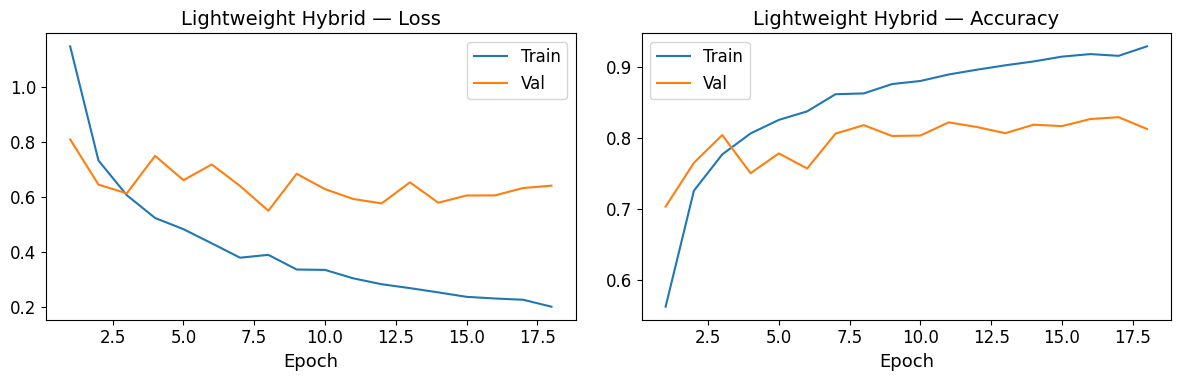

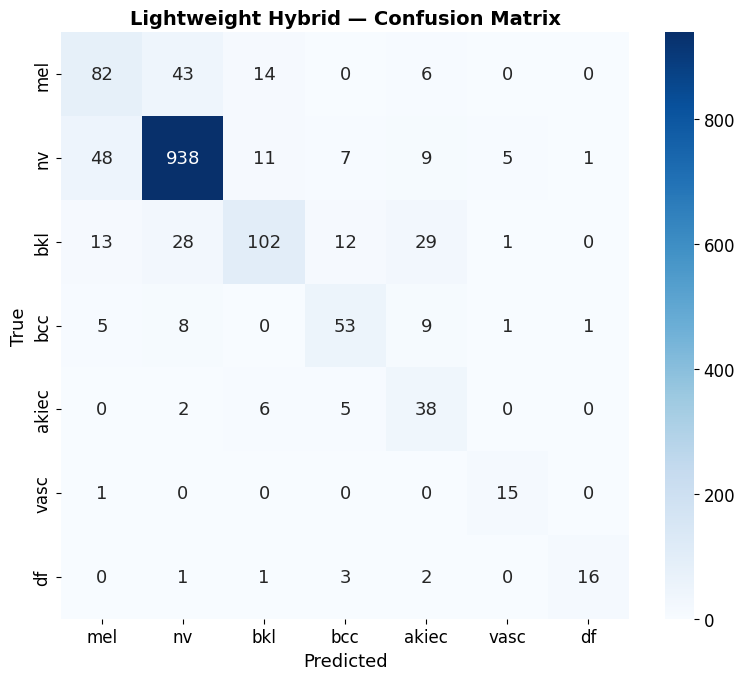

In [16]:
def full_metrics(y_true, y_pred, y_prob, class_names, model_name='Model'):
    acc      = float((np.asarray(y_true) == np.asarray(y_pred)).mean())
    bal_acc  = balanced_accuracy_score(y_true, y_pred)
    kappa_c  = cohen_kappa_score(y_true, y_pred)                      # Cohen's kappa (unweighted), the right one for nominal classes
    kappa    = cohen_kappa_score(y_true, y_pred, weights='quadratic') # quadratic-weighted kappa, listed in the project proposal
    report   = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    macro_f1 = report['macro avg']['f1-score']
    auroc    = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')

    print(f'\n=== {model_name} — Test Set Results ===')
    print(f'  Accuracy          : {acc:.4f}')
    print(f'  Balanced Accuracy : {bal_acc:.4f}')
    print(f'  Macro F1-Score    : {macro_f1:.4f}')
    print(f'  Macro AUROC       : {auroc:.4f}')
    print(f'  Cohen Kappa       : {kappa_c:.4f}')
    print(f'  Quadratic Kappa   : {kappa:.4f}')
    print()
    print(classification_report(y_true, y_pred, target_names=class_names))
    return {'model': model_name, 'acc': acc, 'bal_acc': bal_acc, 'macro_f1': macro_f1,
            'auroc': auroc, 'kappa': kappa, 'kappa_cohen': kappa_c}


def plot_confusion_matrix(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{title} — Confusion Matrix', fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'/content/cm_{title.replace(" ","_")}.png', dpi=150)
    plt.show()


def plot_training_curves(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ep = range(1, len(history['train_loss']) + 1)
    ax1.plot(ep, history['train_loss'], label='Train'); ax1.plot(ep, history['val_loss'], label='Val')
    ax1.set_title(f'{title} — Loss'); ax1.set_xlabel('Epoch'); ax1.legend()
    ax2.plot(ep, history['train_acc'], label='Train'); ax2.plot(ep, history['val_acc'], label='Val')
    ax2.set_title(f'{title} — Accuracy'); ax2.set_xlabel('Epoch'); ax2.legend()
    plt.tight_layout()
    plt.savefig(f'/content/curves_{title.replace(" ","_")}.png', dpi=150)
    plt.show()


# Evaluate the hybrid model
_, _, h_preds, h_labels, h_probs = evaluate(hybrid_model, test_loader, criterion_eval, device)
hybrid_metrics = full_metrics(h_labels, h_preds, h_probs, CLASS_NAMES, 'Lightweight Hybrid')

if 'hybrid_history' in globals():
    plot_training_curves(hybrid_history, 'Lightweight Hybrid')
else:
    print('No saved training history was found, so the training-curve plot is skipped.')
plot_confusion_matrix(h_labels, h_preds, CLASS_NAMES, 'Lightweight Hybrid')

### 2.5 Contribution of the Transformer at 448 px

The main model is trained a second time with its Transformer encoder removed (the patch tokens are mean pooled instead) and everything else identical. The difference between the two rows is what the Transformer adds at this resolution. The comparison with EfficientNet-B3 and ViT-B/16 under an equal budget is in Phase 6.2.

In [17]:
all_results = [hybrid_metrics]
if RUN_MAIN_NO_TRANSFORMER:
    r = run_experiment('main448_no_transformer', lambda: make_hybrid(IMG_SIZE, use_transformer=False), img_size=IMG_SIZE,
                       weighted_loss=MS_WEIGHTED_LOSS, use_sampler=MS_SAMPLER, images=MS_IMAGES,
                       epochs=50, patience=10, seed=SEED)
    row = {k: r[k] for k in hybrid_metrics}
    row['model'] = 'Hybrid without Transformer'
    all_results.append(row)

results_df = pd.DataFrame(all_results)
print(f'\n=== Main model at {IMG_SIZE} px, with and without the Transformer ===')
print(results_df[['model', 'acc', 'bal_acc', 'macro_f1', 'auroc', 'kappa_cohen']].round(4).to_string(index=False))


=== main448_no_transformer | img 448 | weighted_loss=False sampler=True images=conservative epochs<=50 seed=42 ===
[main448_no_transformer] Epoch   1/50 | Train Loss: 1.0657 Acc: 0.5871 | Val Loss: 0.7916 Acc: 0.7103
[main448_no_transformer] Epoch   2/50 | Train Loss: 0.6887 Acc: 0.7364 | Val Loss: 0.5958 Acc: 0.7811
[main448_no_transformer] Epoch   3/50 | Train Loss: 0.5683 Acc: 0.7898 | Val Loss: 0.5718 Acc: 0.8128
[main448_no_transformer] Epoch   4/50 | Train Loss: 0.4852 Acc: 0.8217 | Val Loss: 0.6561 Acc: 0.7725
[main448_no_transformer] Epoch   5/50 | Train Loss: 0.4467 Acc: 0.8371 | Val Loss: 0.6470 Acc: 0.7738
[main448_no_transformer] Epoch   6/50 | Train Loss: 0.3902 Acc: 0.8559 | Val Loss: 0.5968 Acc: 0.7917
[main448_no_transformer] Epoch   7/50 | Train Loss: 0.3568 Acc: 0.8692 | Val Loss: 0.5805 Acc: 0.8009
[main448_no_transformer] Epoch   8/50 | Train Loss: 0.3410 Acc: 0.8720 | Val Loss: 0.5818 Acc: 0.7970
[main448_no_transformer] Epoch   9/50 | Train Loss: 0.2993 Acc: 0.88

---
# Phase 3 — Explainability Analysis
**Covers:** Grad-CAM · SHAP DeepExplainer · Native Transformer attention maps  
All explanations are assessed qualitatively against the **ABCDE rule** (Asymmetry, Border, Colour, Diameter, Evolution)

### 3.1 Grad-CAM

Grad-CAM uses gradients of the predicted class score with respect to the last convolutional feature map to produce a spatial heatmap. Clinically, activations over the lesion boundary and colour variation regions indicate the model is using ABCDE-relevant features.

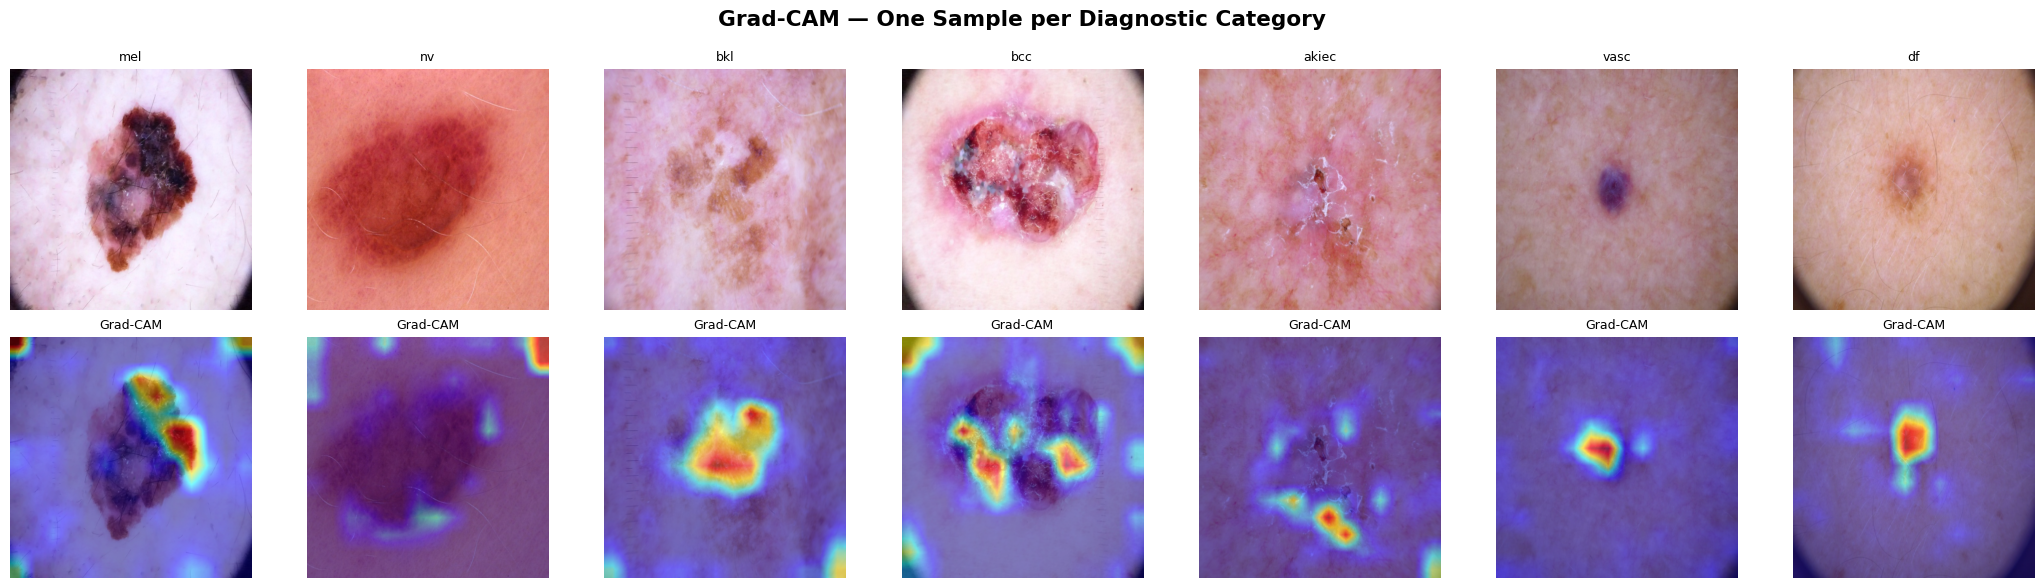

In [18]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Hook onto the last block of the MobileNetV3 feature extractor
target_layers = [hybrid_model.cnn_backbone[-1]]
cam = GradCAM(model=hybrid_model, target_layers=target_layers)

unnorm = transforms.Normalize(
    mean=[-m/s for m, s in zip(MEAN, STD)],
    std=[1/s for s in STD]
)


def gradcam_panel(model, cam, dataset, class_names, save_path='/content/gradcam.png'):
    """One Grad-CAM overlay per class, side-by-side with original."""
    fig, axes = plt.subplots(2, 7, figsize=(21, 6))
    shown = set()

    for idx in range(len(dataset)):
        img_t, label = dataset[idx]
        if label in shown:
            continue
        shown.add(label)

        input_b = img_t.unsqueeze(0).to(device)
        grayscale_cam = cam(input_tensor=input_b,
                            targets=[ClassifierOutputTarget(label)])[0]

        rgb = np.clip(unnorm(img_t).permute(1, 2, 0).numpy(), 0, 1)
        overlay = show_cam_on_image(rgb, grayscale_cam, use_rgb=True)

        col = label
        axes[0, col].imshow(rgb);     axes[0, col].set_title(class_names[label], fontsize=9)
        axes[1, col].imshow(overlay); axes[1, col].set_title('Grad-CAM', fontsize=9)
        for row in range(2):
            axes[row, col].axis('off')

        if len(shown) == 7:
            break

    axes[0, 0].set_ylabel('Original',  fontsize=10)
    axes[1, 0].set_ylabel('Grad-CAM',  fontsize=10)
    plt.suptitle('Grad-CAM — One Sample per Diagnostic Category', fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


gradcam_panel(hybrid_model, cam, test_ds, CLASS_NAMES)

# Remove Grad-CAM's forward hooks now that the figure is made. Left attached, every later forward pass of
# hybrid_model stores a copy of its feature maps in RAM (enough to crash the runtime in Phase 6.8)
# and the extra copy also slows the model down in the latency benchmark.
cam.activations_and_grads.release()

### 3.2 SHAP DeepExplainer

SHAP assigns per-pixel attribution scores indicating each pixel's positive or negative contribution toward the predicted class. Red regions push toward the prediction; blue regions push against it.

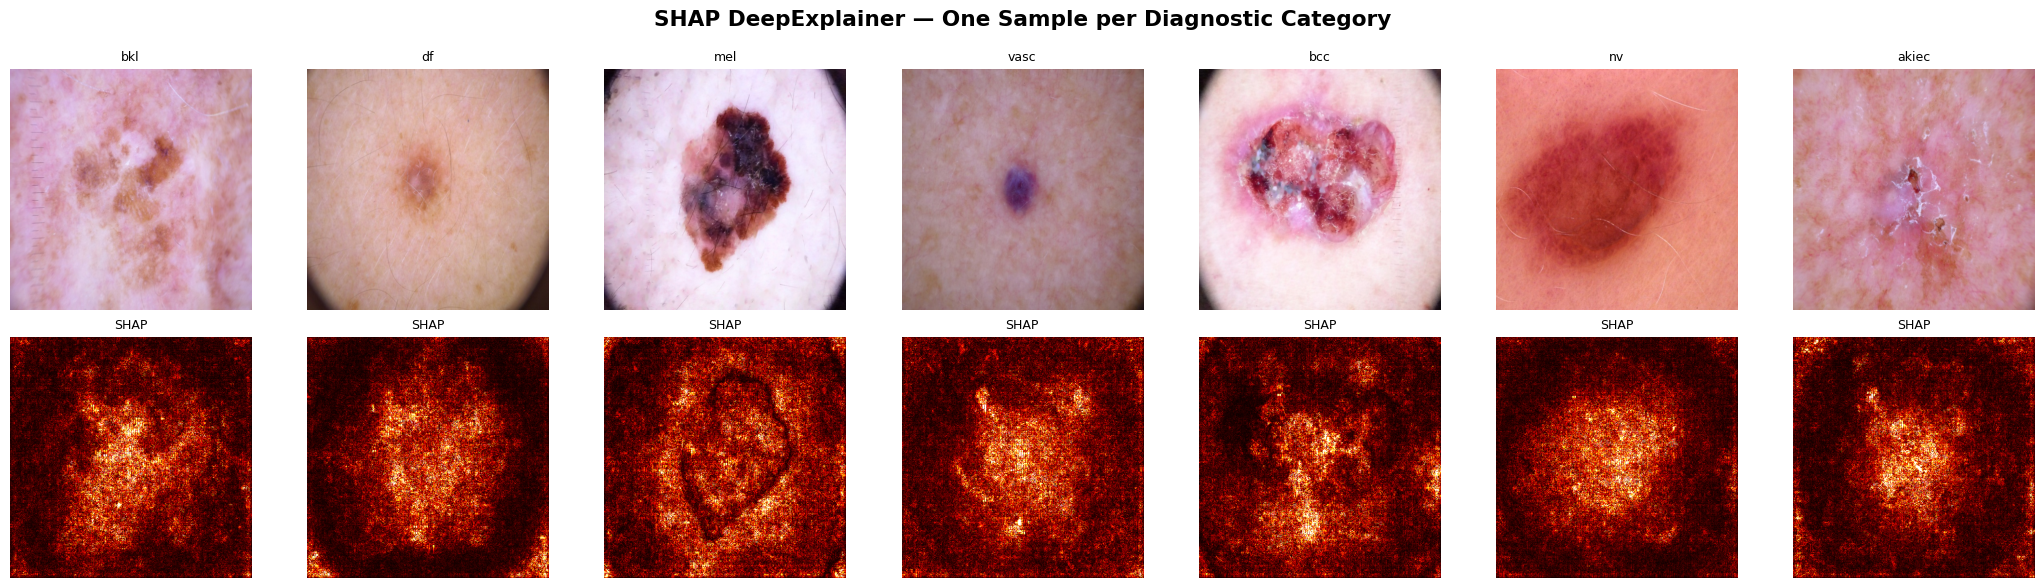

SHAP complete. InvertedResidual forward restored.


In [19]:
import shap
import random
import copy
from torchvision.models.mobilenetv3 import InvertedResidual

def _safe_inverted_residual_forward(self, input):
    result = self.block(input)
    if self.use_res_connect:
        result = result + input.clone()
    return result

_original_inverted_residual_forward = InvertedResidual.forward
InvertedResidual.forward = _safe_inverted_residual_forward

def replace_inplace_activations(model):
    for name, module in model.named_children():
        if isinstance(module, (nn.Hardswish, nn.ReLU, nn.SiLU)):
            setattr(model, name, module.__class__(inplace=False))
        else:
            replace_inplace_activations(module)

shap_compatible_hybrid_model = copy.deepcopy(hybrid_model)
replace_inplace_activations(shap_compatible_hybrid_model)


def shap_panel(model, dataset, device, class_names, num_background=30, save_path='/content/shap.png'):
    model.eval()

    bg_idx     = random.sample(range(len(dataset)), num_background)
    background = torch.stack([dataset[i][0] for i in bg_idx]).to(device)
    explainer  = shap.DeepExplainer(model, background)

    explain_imgs, explain_labels = [], []
    seen = set()
    for i in range(len(dataset)):
        img, lbl = dataset[i]
        if lbl not in seen:
            seen.add(lbl)
            explain_imgs.append(img)
            explain_labels.append(lbl)
        if len(seen) == len(class_names):
            break

    explain_tensor = torch.stack(explain_imgs).to(device)
    shap_values    = explainer.shap_values(explain_tensor, check_additivity=False)

    # SHAP returns the values in different layouts depending on its version; pick the right indexing
    if isinstance(shap_values, list) and len(shap_values) == len(class_names):
        # list of 7 arrays each (N, C, H, W)
        def get_sv(col, lbl): return shap_values[lbl][col]
    elif isinstance(shap_values, list) and len(shap_values) == len(explain_imgs):
        # list of N arrays each (C, H, W, num_classes)
        def get_sv(col, lbl): return shap_values[col][:, :, lbl]
    elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 5:
        # (N, C, H, W, num_classes)
        def get_sv(col, lbl): return shap_values[col, :, :, :, lbl]
    else:
        # fallback: treat first dim as classes
        def get_sv(col, lbl): return shap_values[col]

    fig, axes = plt.subplots(2, len(class_names), figsize=(21, 6))
    for col, (img_t, lbl) in enumerate(zip(explain_imgs, explain_labels)):
        rgb    = np.clip(unnorm(img_t).permute(1, 2, 0).numpy(), 0, 1)
        sv     = get_sv(col, lbl)
        sv_mean = np.abs(sv).mean(0)
        p_low, p_high = np.percentile(sv_mean, 1), np.percentile(sv_mean, 99)
        sv_norm = np.clip((sv_mean - p_low) / (p_high - p_low + 1e-8), 0, 1)

        axes[0, col].imshow(rgb)
        axes[0, col].set_title(class_names[lbl], fontsize=9)
        axes[1, col].imshow(sv_norm, cmap='hot')
        axes[1, col].set_title('SHAP', fontsize=9)
        for row in range(2):
            axes[row, col].axis('off')

    axes[0, 0].set_ylabel('Original',        fontsize=10)
    axes[1, 0].set_ylabel('SHAP Attribution', fontsize=10)
    plt.suptitle('SHAP DeepExplainer — One Sample per Diagnostic Category', fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


shap_panel(shap_compatible_hybrid_model, test_ds, device, CLASS_NAMES)

InvertedResidual.forward = _original_inverted_residual_forward
print('SHAP complete. InvertedResidual forward restored.')

### 3.3 Transformer Attention Maps

Attention from the CLS token to each patch token in the final Transformer layer reveals which image regions the model attends to when making its global contextual decision.

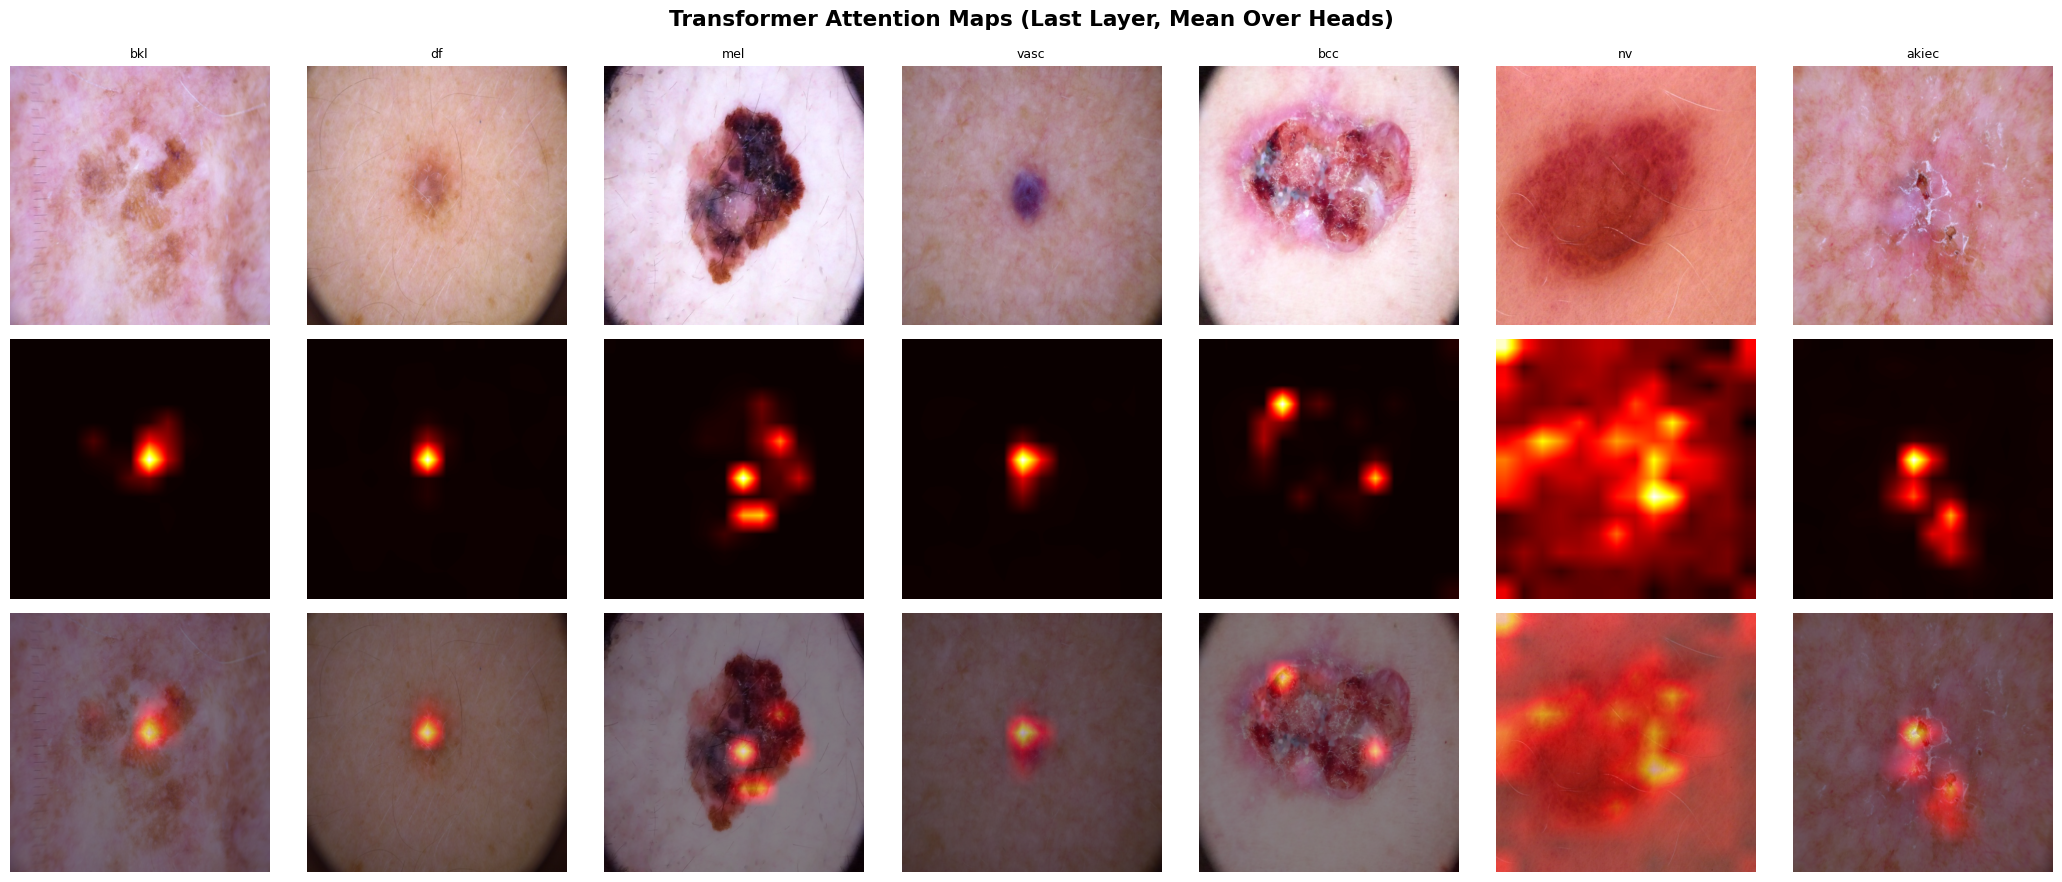

In [20]:
def attention_map_panel(model, dataset, device, class_names, save_path='/content/attention_maps.png'):
    model.eval()

    samples, labels = [], []
    seen = set()
    for i in range(len(dataset)):
        img, lbl = dataset[i]
        if lbl not in seen:
            seen.add(lbl); samples.append(img); labels.append(lbl)
        if len(seen) == 7:
            break

    fig, axes = plt.subplots(3, 7, figsize=(21, 9))

    for col, (img_t, lbl) in enumerate(zip(samples, labels)):
        with torch.no_grad():
            attn_list, H, W = model.get_attention_weights(img_t.unsqueeze(0).to(device))

        # Last layer, average over heads, CLS-to-patch attention
        last_attn = attn_list[-1][0].mean(0)[0, 1:]   # (H*W,)
        attn_map  = last_attn.reshape(H, W).numpy()
        attn_map  = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min() + 1e-8)
        attn_up   = cv2.resize(attn_map, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

        rgb = np.clip(unnorm(img_t).permute(1, 2, 0).numpy(), 0, 1)

        axes[0, col].imshow(rgb);               axes[0, col].set_title(class_names[lbl], fontsize=9)
        axes[1, col].imshow(attn_up, cmap='hot')
        axes[2, col].imshow(rgb)
        axes[2, col].imshow(attn_up, cmap='hot', alpha=0.5)
        for row in range(3):
            axes[row, col].axis('off')

    for lbl, row in zip(['Original', 'Attn Map', 'Overlay'], axes):
        row[0].set_ylabel(lbl, fontsize=10)

    plt.suptitle('Transformer Attention Maps (Last Layer, Mean Over Heads)', fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


attention_map_panel(hybrid_model, test_ds, device, CLASS_NAMES)

---
# Phase 4 — Ablation Study
**Covers:** the contribution of each design decision, measured by changing one thing at a time.

The reference is the pipeline of the main model at 224 px: ImageNet weights, class-balanced sampler with plain cross entropy, Transformer, conservative hair removal. All runs use **224 px, up to 20 epochs, patience 5, dropout 0.3, one seed**, with the same augmentation and optimiser. Each row differs from the reference in exactly one respect.

| Configuration | What changes relative to the reference |
|---|---|
| `ref` | nothing |
| `no_pretrain` | random initial weights |
| `add_weighted_loss` | class-weighted loss added on top of the sampler (imbalance corrected twice) |
| `weighted_loss_only` | class-weighted loss, shuffled batches (no sampler) |
| `no_imbalance_handling` | plain cross entropy, shuffled batches |
| `no_transformer` | Transformer removed, patch tokens mean pooled |
| `no_hair_removal` | original images |
| `aggressive_hair_removal` | plain black-hat threshold hair removal |
| `res112` | 112 px input |

`ref` and `no_transformer` are the first-seed runs of the multi-seed comparison (Phase 6.2), so they are trained once and shared.


=== ms_wl0_sm1_conservative_Hybrid_s42 | img 224 | weighted_loss=False sampler=True images=conservative epochs<=20 seed=42 ===
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   1/20 | Train Loss: 1.1821 Acc: 0.5536 | Val Loss: 0.8015 Acc: 0.6839
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   2/20 | Train Loss: 0.7904 Acc: 0.7016 | Val Loss: 0.6988 Acc: 0.7183
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   3/20 | Train Loss: 0.7041 Acc: 0.7364 | Val Loss: 0.6873 Acc: 0.7586
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   4/20 | Train Loss: 0.6151 Acc: 0.7660 | Val Loss: 0.8760 Acc: 0.7037
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   5/20 | Train Loss: 0.6001 Acc: 0.7732 | Val Loss: 0.6903 Acc: 0.7520
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   6/20 | Train Loss: 0.5285 Acc: 0.8013 | Val Loss: 0.6560 Acc: 0.7698
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   7/20 | Train Loss: 0.4739 Acc: 0.8274 | Val Loss: 0.6792 Acc: 0.7778
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   8/20 | Train Loss: 0.4564 Acc

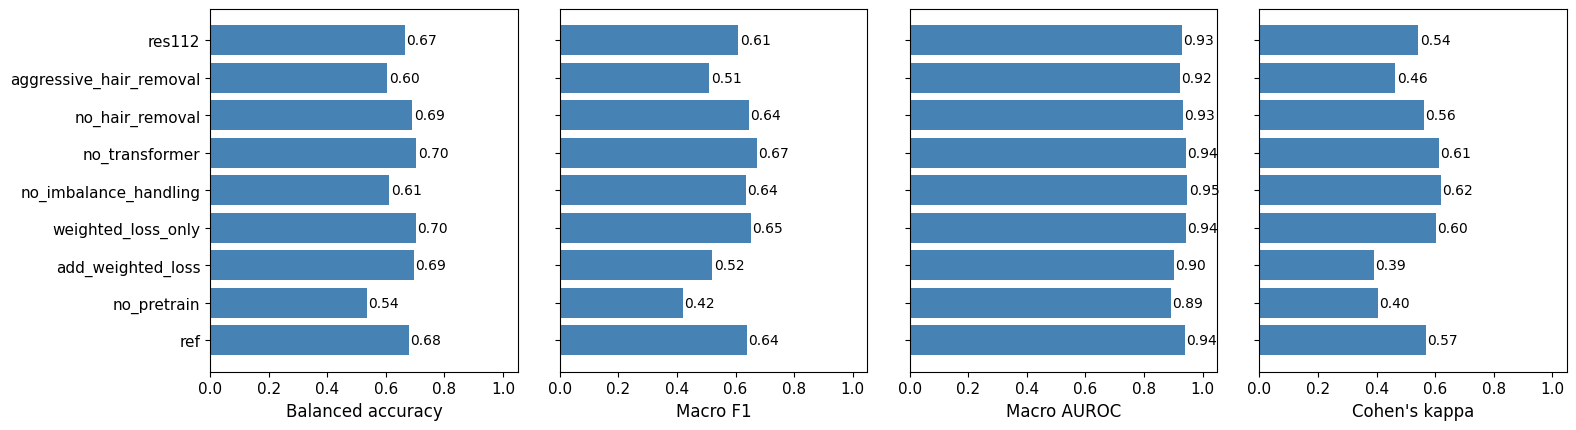


A single seed is one draw. Differences below about 0.02 in balanced accuracy should be called "no clear difference".


In [21]:
S0   = SEEDS[0]
BASE = dict(img_size=224, weighted_loss=MS_WEIGHTED_LOSS, use_sampler=MS_SAMPLER, images=MS_IMAGES)
ABL = [   # (name in the table, cache key, what differs from BASE)
    ('ref',                     ms_key('Hybrid', S0),                     dict(model_fn=lambda: make_hybrid(224))),
    ('no_pretrain',             'abl_no_pretrain',                        dict(model_fn=lambda: make_hybrid(224, pretrained=False))),
    ('add_weighted_loss',       'abl_add_weighted_loss',                  dict(model_fn=lambda: make_hybrid(224), weighted_loss=True, use_sampler=True)),
    ('weighted_loss_only',      'abl_weighted_loss_only',                 dict(model_fn=lambda: make_hybrid(224), weighted_loss=True, use_sampler=False)),
    ('no_imbalance_handling',   'abl_no_imbalance_handling',              dict(model_fn=lambda: make_hybrid(224), weighted_loss=False, use_sampler=False)),
    ('no_transformer',          ms_key('Hybrid without Transformer', S0), dict(model_fn=lambda: make_hybrid(224, use_transformer=False))),
    ('no_hair_removal',         'abl_no_hair_removal',                    dict(model_fn=lambda: make_hybrid(224), images='raw')),
    ('aggressive_hair_removal', 'abl_aggressive_hair_removal',            dict(model_fn=lambda: make_hybrid(224), images='aggressive')),
    ('res112',                  'abl_res112',                             dict(model_fn=lambda: make_hybrid(112), img_size=112)),
]

if RUN_ABLATION:
    for label, key, change in ABL:
        run_experiment(key, seed=S0, epochs=20, patience=5, **{**BASE, **change})

res = load_results()
rows = [dict(config=label, **{m: res[key][m] for m in ['acc', 'bal_acc', 'macro_f1', 'auroc', 'kappa_cohen']},
             best_epoch=res[key]['history'].get('best_epoch'))
        for label, key, _ in ABL if key in res]
abl_new = pd.DataFrame(rows)
print(abl_new.round(4).to_string(index=False))
if len(abl_new):
    print('\nLaTeX rows:')
    for r in abl_new.itertuples(index=False):
        print(f'{r[0].replace("_", " ")} & {r[1]:.3f} & {r[2]:.3f} & {r[3]:.3f} & {r[4]:.3f} & {r[5]:.3f} \\\\')
    # one panel per metric
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), sharey=True)
    for ax, mname, lab in zip(axes, ['bal_acc', 'macro_f1', 'auroc', 'kappa_cohen'],
                              ['Balanced accuracy', 'Macro F1', 'Macro AUROC', "Cohen's kappa"]):
        ax.barh(abl_new['config'], abl_new[mname], color='steelblue')
        ax.set_xlabel(lab, fontsize=12); ax.tick_params(labelsize=11); ax.invert_yaxis()
        for i, v in enumerate(abl_new[mname]):
            ax.text(v + 0.005, i, f'{v:.2f}', va='center', fontsize=10)
        ax.set_xlim(0, 1.05)
    plt.tight_layout(); plt.savefig('/content/ablation_v2.png', dpi=200); plt.show()
print('\nA single seed is one draw. Differences below about 0.02 in balanced accuracy should be called "no clear difference".')

---
# Phase 5 — Few-Shot and Zero-Shot Learning (Exploratory)
**Covers:**
- **Few-shot:** prototypical classification of the three rarest classes (dermatofibroma, vascular lesion, actinic keratosis)
- **Zero-shot:** CLIP classification from textual disease descriptions, and the CLIP lesion gate used in the web application

### 5.1 Few-Shot Learning — Prototypical Classification

A class prototype is the mean embedding of *k* support images; a query image is assigned to the nearest prototype.

* **200 random 3-way episodes**. Support images come from the **training** split and query images from the **test** split (15 per class).
* Three embeddings are compared: the trained hybrid (which has seen these classes), a plain ImageNet MobileNetV3 (which has never seen skin images), and, if `RUN_NOVEL_FS` is on, a hybrid trained on only mel, nv, bkl and bcc, for which df, vasc and akiec are genuinely unseen.
* Chance for 3-way classification is 33.3%. Episodes draw from the same image pool, so the interval describes variation between episodes.

In [22]:
class PrototypicalEncoder(nn.Module):
    """Re-use the trained hybrid model's CNN backbone + Transformer as the embedding network."""
    def __init__(self, base_model):
        super().__init__()
        self.cnn_backbone = base_model.cnn_backbone
        self.patch_proj   = base_model.patch_proj
        self.cls_token    = base_model.cls_token
        self.pos_embed    = base_model.pos_embed
        self.transformer  = base_model.transformer
        self.norm         = base_model.norm

    def forward(self, x):
        feat   = self.cnn_backbone(x)
        B, C, H, W = feat.shape
        tokens = self.patch_proj(feat.flatten(2).transpose(1, 2))
        cls    = self.cls_token.expand(B, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos_embed
        tokens = self.norm(self.transformer(tokens))
        return tokens[:, 0]  # CLS embedding


FS_CLASSES = [LABEL_MAP[c] for c in ['df', 'vasc', 'akiec']]

@torch.no_grad()
def embed_images(embed_fn, df, size):
    tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    ds = HAMDataset(df, tf, 'clean_path'); ld = DataLoader(ds, batch_size=32, num_workers=2)
    out = []
    for x, _ in ld:
        out.append(embed_fn(x.to(device)).cpu())
    return torch.cat(out).numpy()

def fs_episodes(emb_tr, y_tr, emb_te, y_te, k, n_ep=200, n_q=15, seed=0):
    rng = np.random.default_rng(seed); accs = []
    for _ in range(n_ep):
        protos, qx, qy = [], [], []
        for ci_, c in enumerate(FS_CLASSES):
            s = rng.choice(np.where(y_tr == c)[0], k, replace=False)
            protos.append(emb_tr[s].mean(0))
            pool = np.where(y_te == c)[0]
            q = rng.choice(pool, min(n_q, len(pool)), replace=False)   # vasc has only 16 test images
            qx.append(emb_te[q]); qy += [ci_] * len(q)
        P_ = np.stack(protos); Q = np.concatenate(qx)
        d = ((Q[:, None, :] - P_[None]) ** 2).sum(-1)
        accs.append((d.argmin(1) == np.array(qy)).mean())
    return np.array(accs)

def hybrid_embed(m):
    enc = PrototypicalEncoder(m).to(device).eval()
    return lambda x: enc(x)

mask_tr = np.isin(train_df['label'].values, FS_CLASSES); mask_te = np.isin(test_df['label'].values, FS_CLASSES)
tr_fs, te_fs = train_df[mask_tr].reset_index(drop=True), test_df[mask_te].reset_index(drop=True)
y_tr_fs, y_te_fs = tr_fs['label'].values, te_fs['label'].values

encoders = {}
encoders['Hybrid, classes seen'] = (hybrid_embed(hybrid_model), IMG_SIZE)
imnet = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT).features.to(device).eval()
encoders['ImageNet MobileNetV3 only'] = (lambda x: imnet(x).mean((2, 3)), IMG_SIZE)

if RUN_NOVEL_FS:
    base = [LABEL_MAP[c] for c in ['mel', 'nv', 'bkl', 'bcc']]
    remap = {b: i for i, b in enumerate(base)}
    def sub_df(d):
        d = d[d['label'].isin(base)].copy(); d['label'] = d['label'].map(remap); return d.reset_index(drop=True)
    btr, bvl = sub_df(train_df), sub_df(val_df)
    cw4 = len(btr) / (4 * np.bincount(btr['label'], minlength=4))      # sampling weights
    tf_tr = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
                                transforms.RandomRotation(20), transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
                                transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    tf_v = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    set_seed(42)
    sw = cw4[btr['label'].values]
    ld_tr = DataLoader(HAMDataset(btr, tf_tr), batch_size=16, num_workers=2,
                       sampler=WeightedRandomSampler(sw, len(sw), replacement=True))
    ld_vl = DataLoader(HAMDataset(bvl, tf_v), batch_size=16, num_workers=2)
    novel = LightweightHybridModel(num_classes=4, embed_dim=384, img_size=224, dropout=0.3).to(device)
    novel_path = os.path.join(DRIVE_DIR, 'hybrid_base4_v2_best.pth')   # kept on Drive, so a disconnect does not cost a retrain
    if os.path.exists(novel_path):
        novel.load_state_dict(torch.load(novel_path, map_location=device))
        print('4-class model loaded from Drive, training skipped.')
    else:
        novel, _ = train_model(novel, 'hybrid_base4', ld_tr, ld_vl, num_epochs=15, patience=5,
                               class_weights=None, save_dir='/content/saved_models_p6')
        shutil.copy('/content/saved_models_p6/hybrid_base4_best.pth', novel_path)
    novel.eval()
    encoders['Hybrid, 3 classes UNSEEN (224 px)'] = (hybrid_embed(novel), 224)

fs_rows = []
for name, (fn, size) in encoders.items():
    e_tr, e_te = embed_images(fn, tr_fs, size), embed_images(fn, te_fs, size)
    for k in [1, 5, 10]:
        a = fs_episodes(e_tr, y_tr_fs, e_te, y_te_fs, k)
        fs_rows.append([name, k, a.mean() * 100, a.std(ddof=1) * 100, np.percentile(a, 2.5) * 100, np.percentile(a, 97.5) * 100])
fs_df = pd.DataFrame(fs_rows, columns=['embedding', 'shots', 'mean_acc_%', 'sd', 'p2.5', 'p97.5'])
print(fs_df.round(1).to_string(index=False))
print('\nLaTeX rows:')
for r in fs_df.itertuples(index=False):
    print(f'{r[0]} & {r[1]} & {r[2]:.1f} ({r[4]:.1f} to {r[5]:.1f}) \\\\')

[hybrid_base4] Epoch   1/15 | Train Loss: 0.9228 Acc: 0.6118 | Val Loss: 0.7953 Acc: 0.6553
[hybrid_base4] Epoch   2/15 | Train Loss: 0.7177 Acc: 0.7136 | Val Loss: 0.7199 Acc: 0.6999
[hybrid_base4] Epoch   3/15 | Train Loss: 0.6407 Acc: 0.7482 | Val Loss: 0.5310 Acc: 0.8089
[hybrid_base4] Epoch   4/15 | Train Loss: 0.5784 Acc: 0.7662 | Val Loss: 0.5626 Acc: 0.7742
[hybrid_base4] Epoch   5/15 | Train Loss: 0.5229 Acc: 0.7902 | Val Loss: 0.5775 Acc: 0.7785
[hybrid_base4] Epoch   6/15 | Train Loss: 0.4681 Acc: 0.8215 | Val Loss: 0.5998 Acc: 0.7735
[hybrid_base4] Epoch   7/15 | Train Loss: 0.4200 Acc: 0.8363 | Val Loss: 0.6338 Acc: 0.7778
[hybrid_base4] Epoch   8/15 | Train Loss: 0.3954 Acc: 0.8457 | Val Loss: 0.5933 Acc: 0.7792
Early stopping at epoch 8.
Best model restored from /content/saved_models_p6/hybrid_base4_best.pth
                        embedding  shots  mean_acc_%   sd  p2.5  p97.5
             Hybrid, classes seen      1        89.6  2.7  82.2   93.3
             Hybrid, cl

### 5.2 Zero-Shot Learning — CLIP

CLIP encodes an image and a textual description of each disease; the predicted class is the description with the highest cosine similarity, so no labelled training images are needed. CLIP is scored on the same test images as every other model.

The web application also uses CLIP as a gate that rejects images which are not skin lesions. The gate is evaluated on (i) HAM10000 test images, which should pass, and (ii) non-lesion images, which should be rejected. The default negatives are CIFAR-10 photos, which are easy to tell apart from lesions; put photos of bites, bruises and ordinary skin in `NEG_DIR` for a harder test.

In [23]:
!pip install -q git+https://github.com/openai/CLIP.git
print('CLIP installed.')

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.5 MB/s eta 0:00:00
CLIP installed.


In [24]:
import clip
clip_model, clip_preprocess = clip.load('ViT-B/32', device=device)

# --- zero-shot on the full test set, scored like the other models
CLASS_PROMPTS = {
    'mel':   'a dermoscopic image of melanoma with irregular borders and multiple colours',
    'nv':    'a dermoscopic image of a benign melanocytic nevus with regular round shape and uniform brown colour',
    'bkl':   'a dermoscopic image of benign keratosis with waxy stuck-on appearance',
    'bcc':   'a dermoscopic image of basal cell carcinoma with shiny pearly nodule and arborising vessels',
    'akiec': 'a dermoscopic image of actinic keratosis with scaly rough surface on sun-damaged skin',
    'vasc':  'a dermoscopic image of a vascular lesion with bright red lacunes',
    'df':    'a dermoscopic image of a dermatofibroma with central white patch and peripheral brown ring',
}
with torch.no_grad():
    tf_ = clip_model.encode_text(clip.tokenize([CLASS_PROMPTS[c] for c in CLASS_NAMES]).to(device)).float()
    tf_ = tf_ / tf_.norm(dim=-1, keepdim=True)

@torch.no_grad()
def clip_img_feats(pil_list, bs=64):
    out = []
    for i in range(0, len(pil_list), bs):
        x = torch.stack([clip_preprocess(Image.open(p).convert('RGB') if isinstance(p, str) else p)
                         for p in pil_list[i:i+bs]]).to(device)
        f = clip_model.encode_image(x).float(); out.append((f / f.norm(dim=-1, keepdim=True)))
    return torch.cat(out)

test_f = clip_img_feats(list(test_df['path']))   # paths, loaded batch by batch to save RAM
zs_pred_full = (test_f @ tf_.T).argmax(1).cpu().numpy()
zs_bal = balanced_accuracy_score(h_labels, zs_pred_full)
print(f'CLIP zero-shot, full test set (n={len(h_labels)}): balanced accuracy {zs_bal:.3f}, accuracy {(zs_pred_full==h_labels).mean():.3f}')
print(classification_report(h_labels, zs_pred_full, target_names=CLASS_NAMES, zero_division=0))
mm = np.isin(h_labels, FS_CLASSES)
print('Minority classes (df, vasc, akiec), SAME images for both models:')
clip_min_bal   = balanced_accuracy_score(h_labels[mm], zs_pred_full[mm])
hybrid_min_bal_full = balanced_accuracy_score(h_labels[mm], h_preds[mm])
print('  CLIP   bal acc %.3f' % clip_min_bal)
print('  Hybrid bal acc %.3f' % hybrid_min_bal_full)
print('  (n = %d images: %s)' % (mm.sum(), {CLASS_NAMES[c]: int((h_labels == c).sum()) for c in FS_CLASSES}))

# --- the gate used in the app (same two prompts as app.py)
POS = "a close-up dermoscopic image of a skin lesion or mole"
NEG = "a regular photo of normal skin, a mosquito bite, an insect sting, a bruise, or a non-lesion"
with torch.no_grad():
    g = clip_model.encode_text(clip.tokenize([POS, NEG]).to(device)).float(); g = g / g.norm(dim=-1, keepdim=True)

def pass_rate(feats):
    s = 100.0 * feats @ g.T                               # CLIP logit scale
    return (torch.softmax(s, 1)[:, 0] > torch.softmax(s, 1)[:, 1]).float().cpu().numpy()

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return c - h, c + h

pos = pass_rate(test_f)
gate_pass_rate, gate_reject_rate, gate_neg_name = float(pos.mean()), None, None
lo, hi = wilson(pos.sum(), len(pos))
print(f'\nGate: HAM10000 test images passed {int(pos.sum())}/{len(pos)} = {pos.mean():.3f} (95% CI {lo:.3f} to {hi:.3f})')
by_class = {c: float(pos[h_labels == LABEL_MAP[c]].mean()) for c in CLASS_NAMES}
print('Pass rate by class:', {k: round(v, 3) for k, v in by_class.items()})

NEG_DIR = None      # e.g. '/content/drive/MyDrive/non_lesion_photos'
neg_pils = []
if NEG_DIR and os.path.isdir(NEG_DIR):
    for f in sorted(os.listdir(NEG_DIR)):
        try: neg_pils.append(Image.open(os.path.join(NEG_DIR, f)).convert('RGB'))
        except Exception: pass
    neg_name = 'your own non-lesion photos'
else:
    import torchvision
    c10 = torchvision.datasets.CIFAR10('/content/cifar', train=False, download=True)
    ids = np.random.default_rng(SEED).choice(len(c10), 300, replace=False)
    neg_pils = [c10[int(i)][0].convert('RGB') for i in ids]; neg_name = 'CIFAR-10 photos (easy negatives)'
if neg_pils:
    rej = 1 - pass_rate(clip_img_feats(neg_pils)); lo, hi = wilson(rej.sum(), len(rej))
    gate_reject_rate, gate_neg_name = float(rej.mean()), f'{neg_name}, n={len(rej)}'
    print(f'Gate: {neg_name} rejected {int(rej.sum())}/{len(rej)} = {rej.mean():.3f} (95% CI {lo:.3f} to {hi:.3f})')

100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 136MiB/s]


CLIP zero-shot, full test set (n=1516): balanced accuracy 0.278, accuracy 0.501
              precision    recall  f1-score   support

         mel       0.29      0.16      0.21       145
          nv       0.76      0.68      0.72      1019
         bkl       0.50      0.02      0.04       185
         bcc       0.00      0.00      0.00        77
       akiec       0.20      0.41      0.27        51
        vasc       0.06      0.06      0.06        16
          df       0.04      0.61      0.07        23

    accuracy                           0.50      1516
   macro avg       0.27      0.28      0.20      1516
weighted avg       0.61      0.50      0.52      1516

Minority classes (df, vasc, akiec), SAME images for both models:
  CLIP   bal acc 0.361
  Hybrid bal acc 0.793
  (n = 90 images: {'df': 23, 'vasc': 16, 'akiec': 51})

Gate: HAM10000 test images passed 1489/1516 = 0.982 (95% CI 0.974 to 0.988)
Pass rate by class: {'mel': 0.993, 'nv': 0.981, 'bkl': 0.978, 'bcc': 0.987, 'aki

100%|██████████| 170M/170M [27:39<00:00, 103kB/s] 


Gate: CIFAR-10 photos (easy negatives) rejected 156/300 = 0.520 (95% CI 0.464 to 0.576)


---
# Phase 6 — Extended Evaluation

Statistical confidence, efficiency, robustness and clinical interpretation of the trained models.

* Every training run in this notebook is cached in `final_run_results.json` on Google Drive, so after a disconnect the finished runs are skipped when the notebook is run again.
* The long experiments are controlled by the `RUN_...` flags in the run-configuration cell near the top of the notebook.

In [25]:
# Shared helpers for Phase 6
from sklearn.metrics import f1_score, roc_curve
from scipy import stats

assert 'hybrid_metrics' in globals(), 'Run the Phase 2 evaluation cells first.'
y_test = h_labels


def metric_dict(y, p, pr):
    out = {'acc': float((y == p).mean()),
           'bal_acc': balanced_accuracy_score(y, p),
           'macro_f1': f1_score(y, p, average='macro'),
           'kappa': cohen_kappa_score(y, p)}
    try:
        out['auroc'] = roc_auc_score(y, pr, multi_class='ovr', average='macro')
    except ValueError:
        out['auroc'] = np.nan
    return out

print('Helpers ready.')

Helpers ready.


### 6.1 Class distribution of the train / validation / test splits

In [26]:
rows = []
for c in CLASS_NAMES:
    rows.append([c, int((train_df['dx'] == c).sum()), int((val_df['dx'] == c).sum()), int((test_df['dx'] == c).sum())])
split_tab = pd.DataFrame(rows, columns=['class', 'train', 'val', 'test'])
split_tab.loc[len(split_tab)] = ['total', len(train_df), len(val_df), len(test_df)]
print(split_tab.to_string(index=False))
print('\nShare of nevus: train %.1f%%  val %.1f%%  test %.1f%%' % tuple(
    100 * (d['dx'] == 'nv').mean() for d in (train_df, val_df, test_df)))
print('Majority-class (always nevus) accuracy on test: %.4f' % (test_df['dx'] == 'nv').mean())
print('Smallest validation classes:', split_tab[split_tab['class'].isin(['df', 'vasc'])][['class', 'val']].values.tolist(),
      '-> one validation image moves that class recall by 1/n, so validation curves are noisy.')
print('\nLaTeX rows:')
for r in split_tab.itertuples(index=False):
    print(f'{r[0]} & {r[1]:,} & {r[2]:,} & {r[3]:,} \\\\')

class  train  val  test
  mel    775  193   145
   nv   4728  958  1019
  bkl    734  180   185
  bcc    355   82    77
akiec    235   41    51
 vasc     85   41    16
   df     75   17    23
total   6987 1512  1516

Share of nevus: train 67.7%  val 63.4%  test 67.2%
Majority-class (always nevus) accuracy on test: 0.6722
Smallest validation classes: [['vasc', 41], ['df', 17]] -> one validation image moves that class recall by 1/n, so validation curves are noisy.

LaTeX rows:
mel & 775 & 193 & 145 \\
nv & 4,728 & 958 & 1,019 \\
bkl & 734 & 180 & 185 \\
bcc & 355 & 82 & 77 \\
akiec & 235 & 41 & 51 \\
vasc & 85 & 41 & 16 \\
df & 75 & 17 & 23 \\
total & 6,987 & 1,512 & 1,516 \\


### 6.2 Multi-seed comparison with an equal training budget

The hybrid, the hybrid without its Transformer, EfficientNet-B3 and ViT-B/16 are trained with the **same pipeline, input size (224 px), loss, sampler, optimiser, epoch limit (20) and patience (5)**, over three seeds. This gives a like-for-like comparison, an estimate of the variation between training runs, and training curves for every model.

224 px is used because it is the input size ViT-B/16 requires, so it is the one size all four models share.

Multi-seed settings: weighted loss=False, sampler=True, images=conservative

=== ms_wl0_sm1_conservative_Hybrid_s42 | finished in an earlier session, saved results shown ===
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   1 | Train Loss: 1.1821 Acc: 0.5536 | Val Loss: 0.8015 Acc: 0.6839
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   2 | Train Loss: 0.7904 Acc: 0.7016 | Val Loss: 0.6988 Acc: 0.7183
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   3 | Train Loss: 0.7041 Acc: 0.7364 | Val Loss: 0.6873 Acc: 0.7586
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   4 | Train Loss: 0.6151 Acc: 0.7660 | Val Loss: 0.8760 Acc: 0.7037
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   5 | Train Loss: 0.6001 Acc: 0.7732 | Val Loss: 0.6903 Acc: 0.7520
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   6 | Train Loss: 0.5285 Acc: 0.8013 | Val Loss: 0.6560 Acc: 0.7698
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   7 | Train Loss: 0.4739 Acc: 0.8274 | Val Loss: 0.6792 Acc: 0.7778
[ms_wl0_sm1_conservative_Hybrid_s42] Epoch   8 | 

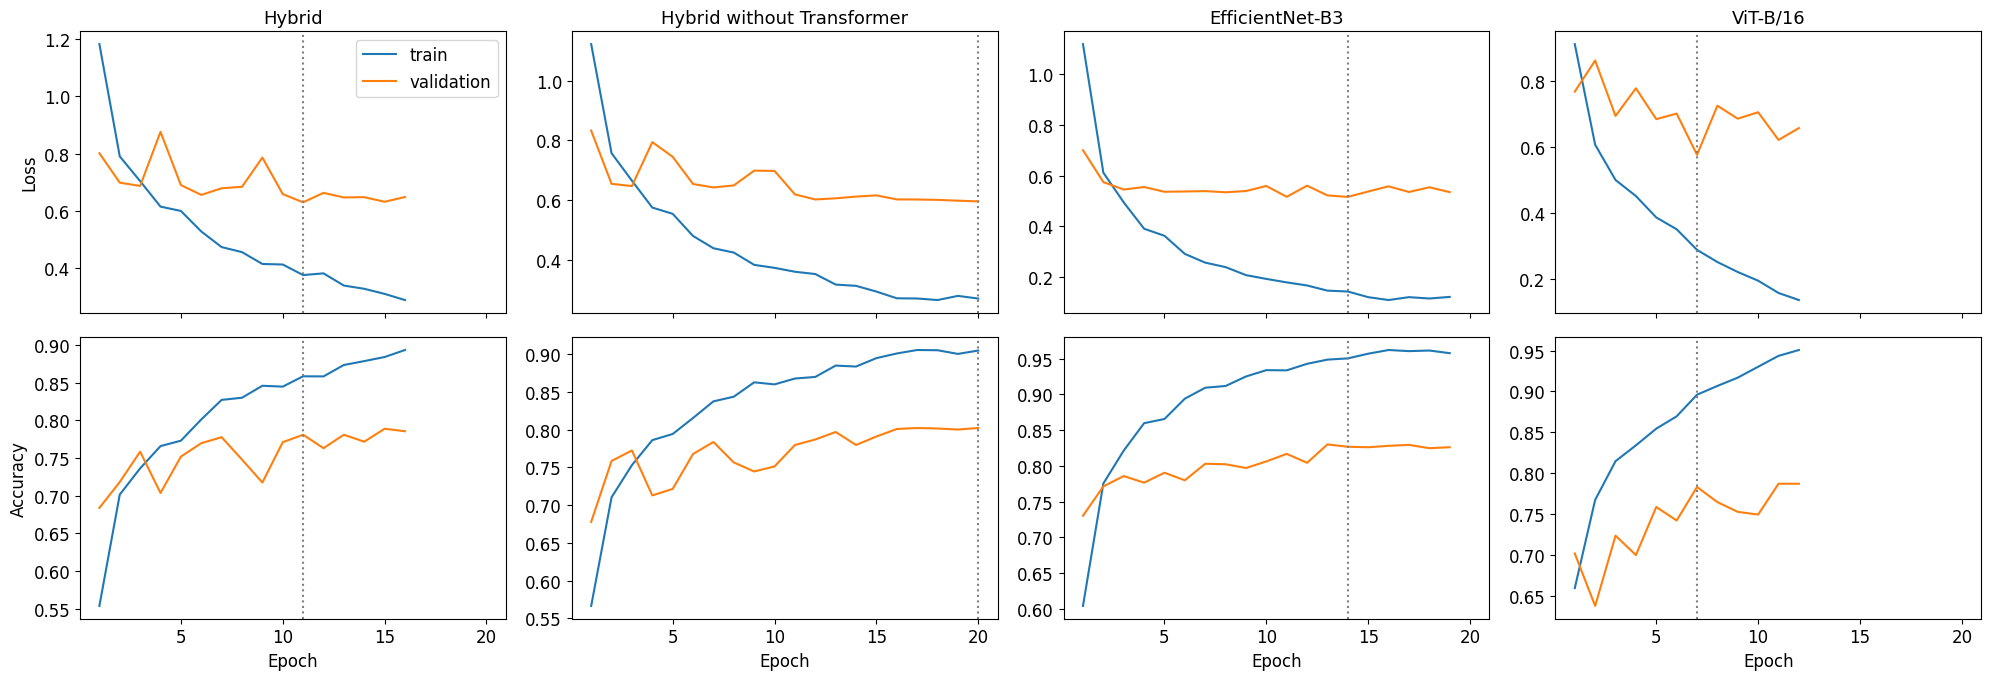

In [27]:
def make_effnet(): return build_efficientnet_b3(NUM_CLASSES).to(device)
def make_vit():    return build_vit_b16(NUM_CLASSES).to(device)

MS_MODELS = {'Hybrid': lambda: make_hybrid(224),
             'Hybrid without Transformer': lambda: make_hybrid(224, use_transformer=False),
             'EfficientNet-B3': make_effnet, 'ViT-B/16': make_vit}

print(f'Multi-seed settings: weighted loss={MS_WEIGHTED_LOSS}, sampler={MS_SAMPLER}, images={MS_IMAGES}')

if RUN_MULTISEED:
    for name, fn in MS_MODELS.items():
        for s in SEEDS:
            run_experiment(ms_key(name, s), fn, img_size=224, epochs=20, patience=5, seed=s,
                           weighted_loss=MS_WEIGHTED_LOSS, use_sampler=MS_SAMPLER, images=MS_IMAGES)

res = load_results()
ms_summary = []
for name in MS_MODELS:
    runs = [res[ms_key(name, s)] for s in SEEDS if ms_key(name, s) in res]
    if not runs: continue
    row = {'model': name, 'n_seeds': len(runs)}
    for k in ['acc', 'bal_acc', 'macro_f1', 'auroc', 'kappa_cohen']:
        v = np.array([r[k] for r in runs]); row[k] = f'{v.mean():.3f} ± {v.std(ddof=1) if len(v) > 1 else float("nan"):.3f}'
    ms_summary.append(row)
if ms_summary:
    ms_df = pd.DataFrame(ms_summary)
    print(ms_df.to_string(index=False))
    # curves for every model (first seed)
    fig, ax = plt.subplots(2, len(MS_MODELS), figsize=(5 * len(MS_MODELS), 7), sharex=True)
    for j, name in enumerate(MS_MODELS):
        h = res.get(ms_key(name, SEEDS[0]), {}).get('history')
        if not h: continue
        ep = range(1, len(h['train_loss']) + 1)
        ax[0, j].plot(ep, h['train_loss'], label='train'); ax[0, j].plot(ep, h['val_loss'], label='validation')
        ax[1, j].plot(ep, h['train_acc'], label='train'); ax[1, j].plot(ep, h['val_acc'], label='validation')
        ax[0, j].set_title(name, fontsize=13); ax[1, j].set_xlabel('Epoch', fontsize=12)
        ax[0, j].axvline(h['best_epoch'], ls=':', c='grey'); ax[1, j].axvline(h['best_epoch'], ls=':', c='grey')
    ax[0, 0].set_ylabel('Loss', fontsize=12); ax[1, 0].set_ylabel('Accuracy', fontsize=12); ax[0, 0].legend()
    plt.tight_layout(); plt.savefig('/content/curves_all_models.png', dpi=200); plt.show()
else:
    print('No multi-seed results yet (RUN_MULTISEED is False).')

### 6.3 Metrics with confidence intervals and paired differences

* Reports plain **accuracy**, **Cohen's kappa** (unweighted, appropriate for nominal classes) and the **majority-class baseline**.
* Confidence intervals use a **lesion-level bootstrap**: whole lesions are resampled, because several images of one lesion are not independent.
* The paired differences use the same resamples for both models, and compare models trained under the same conditions: the main model with and without its Transformer (448 px), and the hybrid against each other model of the multi-seed comparison (224 px, first seed).
* These intervals reflect the test sample only. Variation between training runs is shown by the multi-seed table in 6.2.

In [28]:
def stored(key):
    """Test predictions and probabilities saved by run_experiment."""
    r = load_results()[key]
    p = np.array(r['probs'], dtype=float)
    return np.array(r['preds']), p / p.sum(1, keepdims=True)

res = load_results()
MAIN = f'Hybrid {IMG_SIZE} px (main model)'
MODEL_OUT, PAIRS = {MAIN: (h_preds, h_probs)}, []
if 'main448_no_transformer' in res:
    name_ = f'Hybrid without Transformer {IMG_SIZE} px'
    MODEL_OUT[name_] = stored('main448_no_transformer'); PAIRS.append((MAIN, name_))
ms_names = {}
for name in MS_MODELS:
    if ms_key(name, SEEDS[0]) in res:
        ms_names[name] = f'{name} 224 px (seed {SEEDS[0]})'
        MODEL_OUT[ms_names[name]] = stored(ms_key(name, SEEDS[0]))
if 'Hybrid' in ms_names:
    PAIRS += [(ms_names['Hybrid'], v) for k, v in ms_names.items() if k != 'Hybrid']

lesion_ids = test_df['lesion_id'].values
groups = {l: np.where(lesion_ids == l)[0] for l in np.unique(lesion_ids)}
glist = list(groups.values())
rng = np.random.default_rng(SEED)
boot_idx = []
for _ in range(N_BOOT):
    pick = rng.integers(0, len(glist), len(glist))
    boot_idx.append(np.concatenate([glist[k] for k in pick]))

KEYS = ['acc', 'bal_acc', 'macro_f1', 'auroc', 'kappa']
boot = {m: {k: [] for k in KEYS} for m in MODEL_OUT}
for idx in boot_idx:
    for m, (p, pr) in MODEL_OUT.items():
        d = metric_dict(y_test[idx], p[idx], pr[idx])
        for k in KEYS:
            boot[m][k].append(d[k])

def ci(a):
    a = np.array(a, dtype=float)
    return np.nanpercentile(a, 2.5), np.nanpercentile(a, 97.5)

print('Test metrics, point estimate [95% lesion-bootstrap CI]')
tab = {}
for m, (p, pr) in MODEL_OUT.items():
    pt = metric_dict(y_test, p, pr)
    tab[m] = pt
    print(f'\n{m}')
    for k in KEYS:
        lo, hi = ci(boot[m][k]); print(f'  {k:9s} {pt[k]:.3f} [{lo:.3f}, {hi:.3f}]')

maj = (y_test == LABEL_MAP['nv']).mean()
print(f'\nMajority baseline (always nevus): accuracy {maj:.3f}, balanced accuracy {1/NUM_CLASSES:.3f}, Cohen kappa 0.000')

print('\nPaired differences, first model minus second [95% CI]  (a CI that excludes 0 is not explained by test sampling alone)')
for a_, b_ in PAIRS:
    print(f'{a_}  minus  {b_}')
    for k in KEYS:
        d = np.array(boot[a_][k]) - np.array(boot[b_][k])
        lo, hi = ci(d)
        print(f'  {k:9s} {tab[a_][k]-tab[b_][k]:+.3f} [{lo:+.3f}, {hi:+.3f}]')

print('\nLaTeX rows (Acc, Bal acc, Macro F1, AUROC, Cohen kappa) with CIs:')
for m in MODEL_OUT:
    cells_ = []
    for k in KEYS:
        lo, hi = ci(boot[m][k]); cells_.append(f'{tab[m][k]:.3f} ({lo:.3f} to {hi:.3f})')
    print(m, '&', ' & '.join(cells_), r'\\')

Test metrics, point estimate [95% lesion-bootstrap CI]

Hybrid 448 px (main model)
  acc       0.821 [0.796, 0.844]
  bal_acc   0.729 [0.677, 0.779]
  macro_f1  0.699 [0.644, 0.740]
  auroc     0.946 [0.918, 0.964]
  kappa     0.657 [0.612, 0.697]

Hybrid without Transformer 448 px
  acc       0.784 [0.760, 0.808]
  bal_acc   0.743 [0.692, 0.790]
  macro_f1  0.711 [0.658, 0.751]
  auroc     0.952 [0.935, 0.966]
  kappa     0.621 [0.580, 0.660]

Hybrid 224 px (seed 42)
  acc       0.763 [0.736, 0.788]
  bal_acc   0.679 [0.617, 0.737]
  macro_f1  0.638 [0.575, 0.687]
  auroc     0.939 [0.920, 0.954]
  kappa     0.568 [0.524, 0.612]

Hybrid without Transformer 224 px (seed 42)
  acc       0.786 [0.759, 0.812]
  bal_acc   0.704 [0.642, 0.761]
  macro_f1  0.673 [0.608, 0.724]
  auroc     0.942 [0.926, 0.956]
  kappa     0.614 [0.568, 0.657]

EfficientNet-B3 224 px (seed 42)
  acc       0.823 [0.799, 0.845]
  bal_acc   0.725 [0.669, 0.780]
  macro_f1  0.740 [0.686, 0.784]
  auroc     0.962 [

### 6.4 Efficiency: model size, FLOPs and inference latency

In [29]:
from torch.utils.flop_counter import FlopCounterMode

def bench(model, size, dev, n_warm=10, n_run=50):
    model = model.to(dev).eval()
    x = torch.randn(1, 3, size, size, device=dev)
    with torch.no_grad():
        for _ in range(n_warm):
            model(x)
        if dev.type == 'cuda':
            torch.cuda.synchronize()
        ts = []
        for _ in range(n_run):
            t0 = time.perf_counter(); model(x)
            if dev.type == 'cuda':
                torch.cuda.synchronize()
            ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts)), float(np.percentile(ts, 90))

def gflops(model, size, dev):
    # Counted with autograd ON. Under torch.no_grad() an eval-mode attention layer runs through PyTorch's fused
    # "fast path", which the counter cannot see into, so the Transformer is counted as 0 FLOPs
    # (hybrid 0.5 instead of 3.3 GFLOPs, ViT-B/16 22.5 instead of 33.7).
    model = model.to(dev).eval()
    x = torch.randn(1, 3, size, size, device=dev)
    with FlopCounterMode(display=False) as fc:
        model(x)
    return fc.get_total_flops() / 1e9          # FLOPs (multiply and add counted separately)

cpu = torch.device('cpu')
rows = []
def n_params(m):
    # the no-Transformer variant keeps its unused Transformer weights in memory; they are not counted
    skip = () if getattr(m, 'use_transformer', True) else ('transformer.', 'cls_token', 'pos_embed')
    return sum(p.numel() for k, p in m.named_parameters() if not k.startswith(skip))

# speed and size do not depend on the trained weights, so freshly built models are used for the comparison models
for name, mdl, size in [('Hybrid (ours)', hybrid_model, IMG_SIZE),
                        ('Hybrid without Transformer', make_hybrid(IMG_SIZE, use_transformer=False), IMG_SIZE),
                        ('Hybrid (ours)', make_hybrid(224), 224),
                        ('Hybrid without Transformer', make_hybrid(224, use_transformer=False), 224),
                        ('EfficientNet-B3', build_efficientnet_b3(NUM_CLASSES), 224),
                        ('ViT-B/16', build_vit_b16(NUM_CLASSES), 224)]:
    n = n_params(mdl)
    gf = gflops(mdl, size, cpu)
    g_med = bench(mdl, size, device)[0] if device.type == 'cuda' else float('nan')
    c_med = bench(mdl, size, cpu, n_warm=3, n_run=15)[0]
    mdl.to(device if mdl is hybrid_model else cpu)
    rows.append([name, size, n / 1e6, n * 4 / 2**20, gf, g_med, c_med])
eff = pd.DataFrame(rows, columns=['model', 'input', 'params_M', 'size_MB_fp32', 'GFLOPs', 'GPU_ms_b1', 'CPU_ms_b1'])
print(eff.round(2).to_string(index=False))
vit_gf = float(eff.loc[eff['model'] == 'ViT-B/16', 'GFLOPs'].iloc[0])
if vit_gf < 30:
    print(f'WARNING: ViT-B/16 came out at {vit_gf:.1f} GFLOPs. The accepted figure is about 35 (17.6 GMACs), so on this '
          'PyTorch version the counter is missing the attention layers. Do not report the GFLOPs column.')
print('\nLaTeX rows:')
for r in eff.itertuples(index=False):
    print(f'{r[0]} & {r[1]} & {r[2]:.1f} & {r[3]:.0f} & {r[4]:.1f} & {r[5]:.1f} & {r[6]:.0f} \\\\')
print('Note: FlopCounterMode counts 2 FLOPs per multiply-add.')

                     model  input  params_M  size_MB_fp32  GFLOPs  GPU_ms_b1  CPU_ms_b1
             Hybrid (ours)    448      8.33         31.76    3.31       8.06      50.64
Hybrid without Transformer    448      1.15          4.39    0.52       5.20      19.27
             Hybrid (ours)    224      8.27         31.55    0.84       6.63      20.32
Hybrid without Transformer    224      1.15          4.39    0.13       5.42       8.87
           EfficientNet-B3    224     10.71         40.84    1.92      12.79      64.55
                  ViT-B/16    224     85.80        327.32   33.70      19.13     482.03

LaTeX rows:
Hybrid (ours) & 448 & 8.3 & 32 & 3.3 & 8.1 & 51 \\
Hybrid without Transformer & 448 & 1.2 & 4 & 0.5 & 5.2 & 19 \\
Hybrid (ours) & 224 & 8.3 & 32 & 0.8 & 6.6 & 20 \\
Hybrid without Transformer & 224 & 1.2 & 4 & 0.1 & 5.4 & 9 \\
EfficientNet-B3 & 224 & 10.7 & 41 & 1.9 & 12.8 & 65 \\
ViT-B/16 & 224 & 85.8 & 327 & 33.7 & 19.1 & 482 \\
Note: FlopCounterMode counts 2 FLOPs p

### 6.5 How much of each image does hair removal change?
Measures the fraction of each image that is inpainted by the conservative hair removal used in this project and by the aggressive variant, and shows the images where the most is changed. The effect on accuracy is measured by the `no_hair_removal`, `aggressive_hair_removal` and `ref` rows of the ablation in Phase 4.

Conservative fraction of pixels inpainted: median 0.000, mean 0.011, 90th pct 0.027, max 0.307 | more than 10% changed: 12 of 300 | unchanged: 201
Aggressive   fraction of pixels inpainted: median 0.124, mean 0.161, 90th pct 0.339, max 0.546 | more than 10% changed: 181 of 300 | unchanged: 0


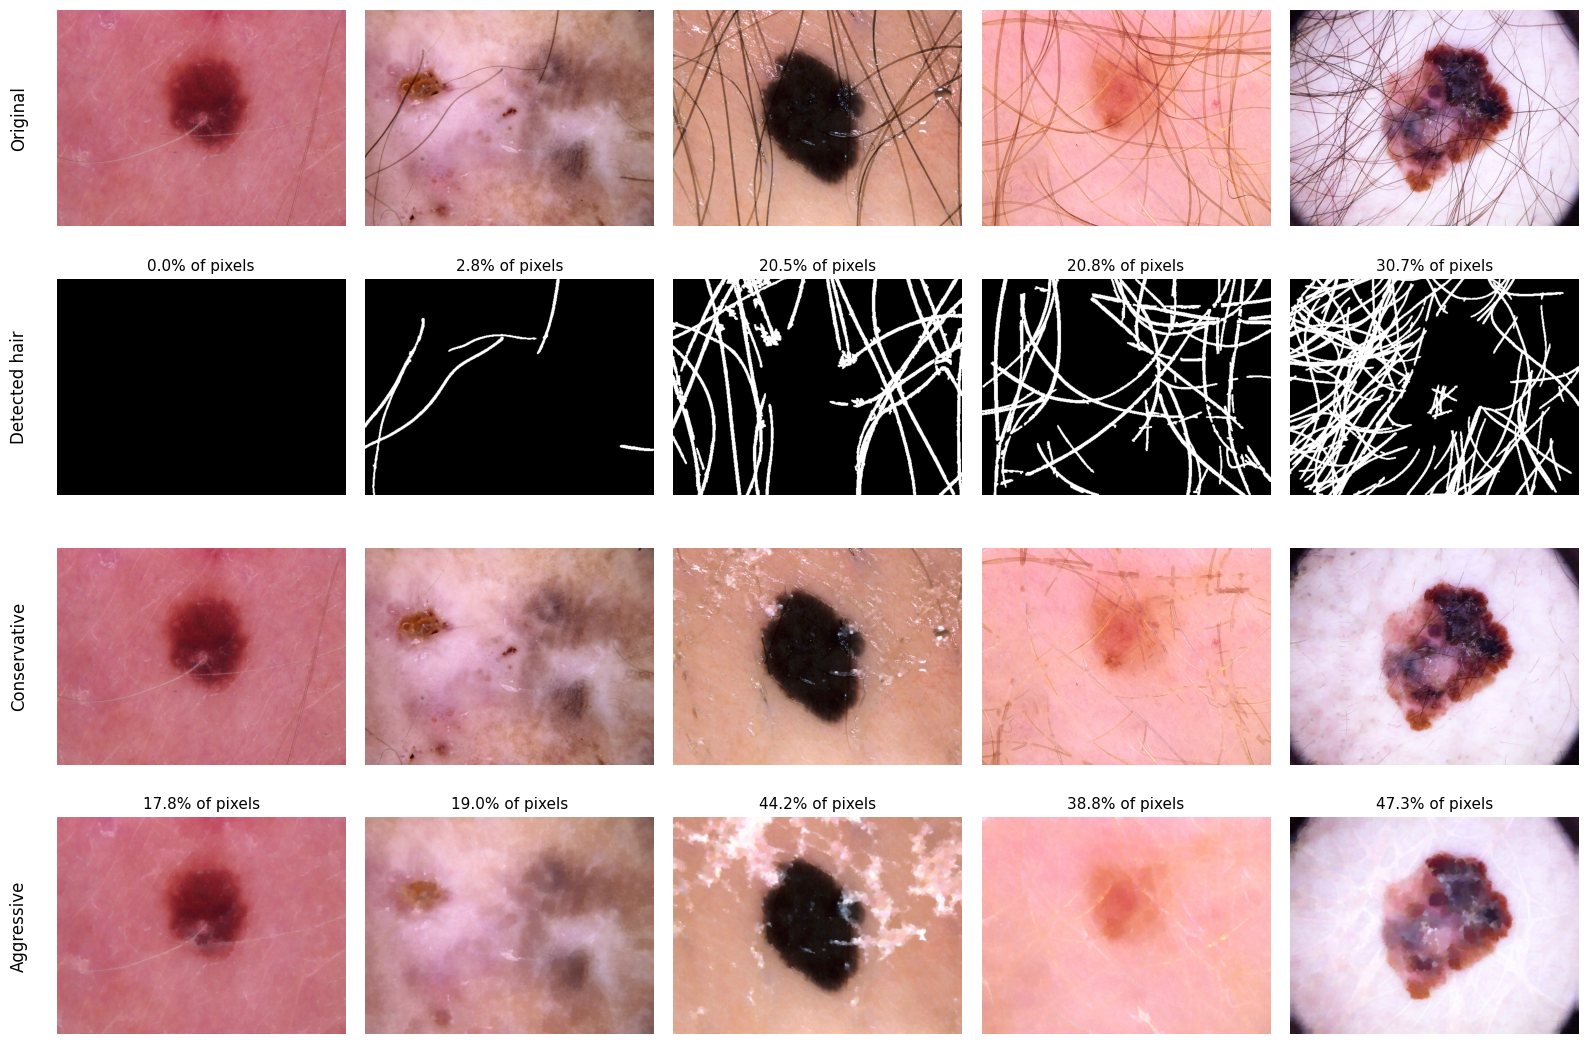

In [30]:
sub = test_df.sample(min(300, len(test_df)), random_state=SEED).reset_index(drop=True)
imgs = [cv2.imread(p) for p in sub['path']]
frac_c = np.array([(hair_mask(im) > 0).mean() for im in imgs])
frac_a = np.array([(aggressive_hair_mask(im) > 0).mean() for im in imgs])
for name, f in [('Conservative', frac_c), ('Aggressive', frac_a)]:
    print('%-12s fraction of pixels inpainted: median %.3f, mean %.3f, 90th pct %.3f, max %.3f | more than 10%% changed: %d of %d | unchanged: %d' %
          (name, np.median(f), f.mean(), np.percentile(f, 90), f.max(), (f > 0.10).sum(), len(f), (f == 0).sum()))

order = np.argsort(frac_c)
show = [order[len(order)//2], order[int(.9*len(order))], order[-3], order[-2], order[-1]]
fig, ax = plt.subplots(4, len(show), figsize=(3.2*len(show), 11))
for j, i in enumerate(show):
    im = imgs[i]
    ax[0, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax[1, j].imshow(hair_mask(im), cmap='gray');                                 ax[1, j].set_title(f'{frac_c[i]*100:.1f}% of pixels', fontsize=11)
    ax[2, j].imshow(cv2.cvtColor(remove_hair(im), cv2.COLOR_BGR2RGB))
    ax[3, j].imshow(cv2.cvtColor(remove_hair_aggressive(im), cv2.COLOR_BGR2RGB)); ax[3, j].set_title(f'{frac_a[i]*100:.1f}% of pixels', fontsize=11)
    for r in range(4): ax[r, j].axis('off')
for r, lab in enumerate(['Original', 'Detected hair', 'Conservative', 'Aggressive']):
    ax[r, 0].text(-0.1, 0.5, lab, transform=ax[r, 0].transAxes, rotation=90, va='center', ha='right', fontsize=12)
plt.tight_layout(); plt.savefig('/content/hair_mask_check.png', dpi=200); plt.show()

### 6.6 Faithfulness of the explanations: deletion and insertion curves

HAM10000 lesions are centred, so a heatmap that sits on the image centre is weak evidence on its own. This test asks whether a map identifies pixels the model **actually relies on**, and whether it does so **better than a fixed centre blob**.

* **Deletion**: remove the most important pixels first (replace them with the mean colour) and track the probability of the predicted class. A faster fall means a better map (lower area is better).
* **Insertion**: start from a blurred image and add the most important pixels first. A faster rise is better (higher area is better).
* Maps compared: Grad-CAM (last convolution block), CLS attention (last layer, mean over heads), a **centre Gaussian**, and **random** noise.
* About 25 test images per class (16 for vasc), with the predicted class as the target. Paired Wilcoxon tests against the centre prior.
* This measures faithfulness to the model, not agreement with a dermatologist.

In [31]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def centre_map(h, w, sigma=0.25):
    yy, xx = np.mgrid[0:h, 0:w]; yy = (yy / (h - 1)) - .5; xx = (xx / (w - 1)) - .5
    return np.exp(-(xx**2 + yy**2) / (2 * sigma**2))

@torch.no_grad()
def prob_of(model, xs, cls):
    return torch.softmax(model(xs), 1)[:, cls].cpu().numpy()

def del_ins_auc(model, x, cls, sal, steps=20):
    # x: (3,H,W) normalised tensor on device, sal: (H,W) numpy. returns (deletion AUC, insertion AUC)
    H, W = sal.shape
    order = np.argsort(-sal.ravel())
    fracs = np.linspace(0, 1, steps + 1)
    mean_img = torch.zeros_like(x)                                    # 0 = dataset mean after normalisation
    blur = torch.from_numpy(cv2.GaussianBlur(x.permute(1, 2, 0).cpu().numpy(), (0, 0), 15)).permute(2, 0, 1).to(x.device)
    dele, ins = [], []
    for f in fracs:
        k = int(f * H * W); m = torch.zeros(H * W, device=x.device); m[torch.from_numpy(order[:k]).to(x.device)] = 1
        m = m.view(1, H, W)
        dele.append(x * (1 - m) + mean_img * m); ins.append(blur * (1 - m) + x * m)
    pd_ = prob_of(model, torch.stack(dele), cls); pi_ = prob_of(model, torch.stack(ins), cls)
    _trap = getattr(np, 'trapezoid', None) or np.trapz      # numpy 2 renamed trapz
    return _trap(pd_, fracs), _trap(pi_, fracs)

def attention_sal(model, x, size):
    with torch.no_grad():
        a, H, W = model.get_attention_weights(x.unsqueeze(0))
    m = a[-1][0].mean(0)[0, 1:].reshape(H, W).numpy()
    return cv2.resize(m, (size, size), interpolation=cv2.INTER_LINEAR)

def gradcam_map(model, x, cls):
    # The hooks are removed as soon as the map is made. Left attached, they would copy the feature maps of
    # every deletion/insertion forward pass into RAM.
    c = GradCAM(model=model, target_layers=[model.cnn_backbone[-1]])
    try:
        return c(input_tensor=x.unsqueeze(0), targets=[ClassifierOutputTarget(cls)])[0]
    finally:
        c.activations_and_grads.release()

xai_res = None
if RUN_XAI_QUANT:
    hybrid_model.eval()
    rng = np.random.default_rng(SEED)
    pick = []
    for c in range(NUM_CLASSES):
        idx = np.where(test_df['label'].values == c)[0]; pick += list(rng.choice(idx, min(25, len(idx)), replace=False))
    centre = centre_map(IMG_SIZE, IMG_SIZE)
    rows = []
    for n_, i in enumerate(pick):
        x, lab = test_ds[i]; x = x.to(device)
        with torch.no_grad():
            cls = int(hybrid_model(x.unsqueeze(0)).argmax(1))
        maps = {'Grad-CAM': gradcam_map(hybrid_model, x, cls),
                'Attention': attention_sal(hybrid_model, x, IMG_SIZE),
                'Centre prior': centre, 'Random': rng.random((IMG_SIZE, IMG_SIZE))}
        for name, sal in maps.items():
            d_, i_ = del_ins_auc(hybrid_model, x, cls, sal)
            rows.append(dict(idx=i, true=lab, pred=cls, method=name, deletion=d_, insertion=i_))
        if (n_ + 1) % 25 == 0: print(f'{n_+1}/{len(pick)} images done')
    xai_res = pd.DataFrame(rows)
    xai_res.to_csv('/content/xai_quant.csv', index=False)
    summ = xai_res.groupby('method')[['deletion', 'insertion']].agg(['mean', 'std']).round(3)
    print(summ)
    for meth in ['Grad-CAM', 'Attention']:
        for met, better in [('deletion', 'lower'), ('insertion', 'higher')]:
            a = xai_res[xai_res.method == meth].set_index('idx')[met]; b = xai_res[xai_res.method == 'Centre prior'].set_index('idx')[met]
            w = stats.wilcoxon(a.values, b.loc[a.index].values)
            print(f'{meth:10s} vs centre prior, {met:9s} ({better} is better): mean diff {np.mean(a.values - b.loc[a.index].values):+.3f}, Wilcoxon p = {w.pvalue:.4f}')
    print('\nShare of images where Grad-CAM beats the centre prior on deletion (lower AUC): %.2f' % (
        (xai_res[xai_res.method == 'Grad-CAM'].set_index('idx')['deletion'] <
         xai_res[xai_res.method == 'Centre prior'].set_index('idx')['deletion']).mean()))

25/164 images done
50/164 images done
75/164 images done
100/164 images done
125/164 images done
150/164 images done
             deletion        insertion       
                 mean    std      mean    std
method                                       
Attention       0.296  0.222     0.641  0.254
Centre prior    0.311  0.242     0.594  0.281
Grad-CAM        0.302  0.243     0.694  0.231
Random          0.245  0.238     0.381  0.290
Grad-CAM   vs centre prior, deletion  (lower is better): mean diff -0.010, Wilcoxon p = 0.9908
Grad-CAM   vs centre prior, insertion (higher is better): mean diff +0.101, Wilcoxon p = 0.0000
Attention  vs centre prior, deletion  (lower is better): mean diff -0.015, Wilcoxon p = 0.6073
Attention  vs centre prior, insertion (higher is better): mean diff +0.047, Wilcoxon p = 0.0000

Share of images where Grad-CAM beats the centre prior on deletion (lower AUC): 0.46


### 6.7 Clinical interpretation, calibration, and the melanoma / nevus confusion

class    n  sensitivity  specificity   PPV   NPV
  mel  145        0.566        0.951 0.550 0.954
   nv 1019        0.921        0.835 0.920 0.837
  bkl  185        0.551        0.976 0.761 0.940
  bcc   77        0.688        0.981 0.662 0.983
akiec   51        0.745        0.962 0.409 0.991
 vasc   16        0.938        0.995 0.682 0.999
   df   23        0.696        0.999 0.889 0.995

LaTeX rows:
mel & 145 & 0.57 & 0.95 & 0.55 & 0.95 \\
nv & 1019 & 0.92 & 0.84 & 0.92 & 0.84 \\
bkl & 185 & 0.55 & 0.98 & 0.76 & 0.94 \\
bcc & 77 & 0.69 & 0.98 & 0.66 & 0.98 \\
akiec & 51 & 0.75 & 0.96 & 0.41 & 0.99 \\
vasc & 16 & 0.94 & 1.00 & 0.68 & 1.00 \\
df & 23 & 0.70 & 1.00 & 0.89 & 1.00 \\

Melanoma vs rest AUROC: 0.899
Mel or BCC (cancer) vs benign/other: sensitivity 0.631, specificity 0.931
Mel, BCC or akiec vs benign: sensitivity 0.725, specificity 0.900

nevus predicted as mel: 48 of 1019 (4.7%); mel predicted as nv: 43 of 145
Share of nv in the training split: 0.677
Test prevalence of mel 

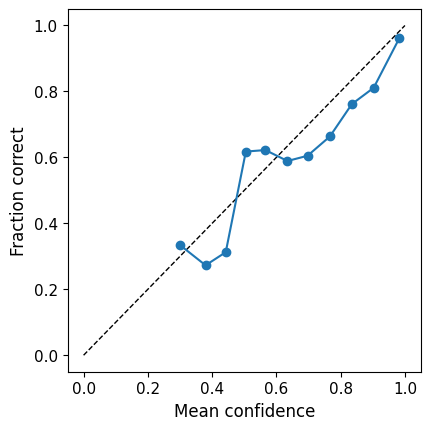

In [32]:
cm = confusion_matrix(y_test, h_preds, labels=range(NUM_CLASSES)); N = cm.sum()
rows = []
for c, name in enumerate(CLASS_NAMES):
    tp = cm[c, c]; fn = cm[c].sum() - tp; fp = cm[:, c].sum() - tp; tn = N - tp - fn - fp
    rows.append([name, cm[c].sum(), tp / (tp + fn), tn / (tn + fp), tp / max(tp + fp, 1), tn / (tn + fn)])
clin = pd.DataFrame(rows, columns=['class', 'n', 'sensitivity', 'specificity', 'PPV', 'NPV'])
print(clin.round(3).to_string(index=False))
print('\nLaTeX rows:')
for r in clin.itertuples(index=False):
    print(f'{r[0]} & {r[1]} & {r[2]:.2f} & {r[3]:.2f} & {r[4]:.2f} & {r[5]:.2f} \\\\')

# melanoma versus everything else
mel = LABEL_MAP['mel']
auc_mel = roc_auc_score(y_test == mel, h_probs[:, mel])
print(f'\nMelanoma vs rest AUROC: {auc_mel:.3f}')
# malignant group: mel, bcc (cancers) ; akiec = pre-cancer, reported separately
MAL = [LABEL_MAP['mel'], LABEL_MAP['bcc']]
yt_m = np.isin(y_test, MAL); yp_m = np.isin(h_preds, MAL)
print('Mel or BCC (cancer) vs benign/other: sensitivity %.3f, specificity %.3f' % (
    (yt_m & yp_m).sum() / yt_m.sum(), (~yt_m & ~yp_m).sum() / (~yt_m).sum()))
yt_m2 = np.isin(y_test, MAL + [LABEL_MAP['akiec']]); yp_m2 = np.isin(h_preds, MAL + [LABEL_MAP['akiec']])
print('Mel, BCC or akiec vs benign: sensitivity %.3f, specificity %.3f' % (
    (yt_m2 & yp_m2).sum() / yt_m2.sum(), (~yt_m2 & ~yp_m2).sum() / (~yt_m2).sum()))

# Where does mel/nv confusion come from?
nv = LABEL_MAP['nv']
print(f'\nnevus predicted as mel: {cm[nv, mel]} of {cm[nv].sum()} ({cm[nv, mel]/cm[nv].sum():.1%}); mel predicted as nv: {cm[mel, nv]} of {cm[mel].sum()}')
print('Share of nv in the training split: %.3f' % (train_df['label'] == nv).mean())
print('Test prevalence of mel %.3f vs effective training prevalence under the sampler 1/7 = %.3f' % ((y_test == mel).mean(), 1/7))

# Expected calibration error (top label, 15 equal-width bins)
def ece(probs, y, bins=15):
    conf = probs.max(1); pred = probs.argmax(1); ok = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1); e = 0.0; pts = []
    for lo_, hi_ in zip(edges[:-1], edges[1:]):
        m = (conf > lo_) & (conf <= hi_)
        if m.any():
            e += m.mean() * abs(ok[m].mean() - conf[m].mean()); pts.append((conf[m].mean(), ok[m].mean(), m.sum()))
    return e, pts
ece_val, pts = ece(h_probs, y_test)
print(f'\nExpected calibration error (hybrid, test): {ece_val:.3f}')
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.plot([p[0] for p in pts], [p[1] for p in pts], 'o-')
ax.set_xlabel('Mean confidence', fontsize=12); ax.set_ylabel('Fraction correct', fontsize=12); ax.tick_params(labelsize=11)
plt.tight_layout(); plt.savefig('/content/reliability.png', dpi=200); plt.show()

### 6.8 Prior shift: adjusting the predictions to the real class frequencies

The sampler and weights make the network behave as if all seven classes were equally common (1/7 each), but the test set is 67% nevus.
Adding `tau * log(prior)` to the logits moves the decision toward the real class frequencies.
`tau` is **chosen on the validation set only** (largest macro F1), then applied once to the test set. `tau = 0` is the current model.
This is a post-hoc operating-point choice. It does not retrain anything.

In [33]:
_, _, v_preds, v_labels, v_probs = evaluate(hybrid_model, val_loader, criterion_eval, device)
prior = np.bincount(train_df['label'].values, minlength=NUM_CLASSES) / len(train_df)

def adjust(p, tau):
    z = np.log(p + 1e-12) + tau * np.log(prior)
    return z.argmax(1)

mel = LABEL_MAP['mel']
def row(y, probs, tau):
    pr = adjust(probs, tau)
    return dict(tau=tau, acc=(pr == y).mean(), bal_acc=balanced_accuracy_score(y, pr), macro_f1=f1_score(y, pr, average='macro'),
                mel_recall=((pr == mel) & (y == mel)).sum() / max((y == mel).sum(), 1),
                mel_precision=((pr == mel) & (y == mel)).sum() / max((pr == mel).sum(), 1))
taus = np.round(np.arange(0, 1.01, 0.1), 2)
val_tab = pd.DataFrame([row(v_labels, v_probs, t) for t in taus])
test_tab = pd.DataFrame([row(y_test, h_probs, t) for t in taus])
best_tau = float(val_tab.loc[val_tab['macro_f1'].idxmax(), 'tau'])
print('VALIDATION'); print(val_tab.round(3).to_string(index=False))
print('\nTEST');       print(test_tab.round(3).to_string(index=False))
print(f'\ntau chosen on validation (max macro F1): {best_tau}')
print('Test at tau=0   :', test_tab[test_tab.tau == 0].round(3).to_dict('records')[0])
print('Test at tau*    :', test_tab[test_tab.tau == best_tau].round(3).to_dict('records')[0])

VALIDATION
 tau   acc  bal_acc  macro_f1  mel_recall  mel_precision
 0.0 0.818    0.707     0.685       0.554          0.608
 0.1 0.820    0.694     0.682       0.523          0.631
 0.2 0.822    0.693     0.686       0.518          0.649
 0.3 0.823    0.687     0.686       0.487          0.671
 0.4 0.825    0.679     0.686       0.472          0.689
 0.5 0.824    0.670     0.683       0.451          0.696
 0.6 0.819    0.652     0.666       0.420          0.698
 0.7 0.814    0.643     0.660       0.394          0.691
 0.8 0.809    0.627     0.650       0.332          0.674
 0.9 0.805    0.611     0.639       0.306          0.663
 1.0 0.802    0.592     0.624       0.275          0.688

TEST
 tau   acc  bal_acc  macro_f1  mel_recall  mel_precision
 0.0 0.821    0.729     0.699       0.566          0.550
 0.1 0.825    0.727     0.702       0.531          0.592
 0.2 0.825    0.715     0.699       0.490          0.597
 0.3 0.828    0.706     0.698       0.483          0.636
 0.4 0.828    

### 6.9 Save all result tables

In [34]:
dump = {'split_table': split_tab.to_dict('records'), 'main_metrics': tab, 'efficiency': eff.to_dict('records'),
        'ablation_v2': abl_new.to_dict('records') if len(abl_new) else [], 'fewshot': fs_df.to_dict('records'),
        'ece': float(ece_val), 'best_tau': best_tau,
        'comparison': results_df.to_dict('records'),
        'multiseed': ms_summary,
        'clip': {'zero_shot_bal_acc_full_test': float(zs_bal), 'minority_bal_acc_clip': float(clip_min_bal),
                 'minority_bal_acc_hybrid': float(hybrid_min_bal_full), 'gate_pass_rate_lesions': gate_pass_rate,
                 'gate_reject_rate_non_lesions': gate_reject_rate, 'gate_negatives': gate_neg_name},
        'xai': xai_res.groupby('method')[['deletion', 'insertion']].mean().reset_index().to_dict('records') if xai_res is not None else [],
        'clinical': clin.to_dict('records')}
with open('/content/drive/MyDrive/final_run_summary.json', 'w') as f:
    json.dump(dump, f, indent=1, default=float)
print('Saved /content/drive/MyDrive/final_run_summary.json')
print('Also download: hair_mask_check.png, ablation_v2.png, curves_all_models.png, reliability.png, xai_quant.csv from /content')

Saved /content/drive/MyDrive/final_run_summary.json
Also download: hair_mask_check.png, ablation_v2.png, curves_all_models.png, reliability.png, xai_quant.csv from /content


---
## Final Summary


In [35]:
# Summary of the results computed in this run
_g = globals()
print('=' * 78)
print('FINAL RESULTS SUMMARY')
print('=' * 78)

print(f'\n1. MAIN MODEL ON THE TEST SET ({IMG_SIZE} px), with and without its Transformer')
print(results_df[['model', 'acc', 'bal_acc', 'macro_f1', 'auroc', 'kappa_cohen']].round(4).to_string(index=False))
print('   Always predicting nevus gives accuracy %.4f, balanced accuracy %.4f, kappa 0.' % (
    (h_labels == LABEL_MAP['nv']).mean(), 1 / NUM_CLASSES))

print('\n2. EQUAL-BUDGET COMPARISON, mean ± sd over seeds (Phase 6.2: all models 224 px, same pipeline)')
print(ms_df.to_string(index=False) if _g.get('ms_summary') else '   not run (RUN_MULTISEED is False)')

print('\n3. ABLATION (Phase 4: 224 px, up to 20 epochs, one seed; compare each row with ref)')
print(abl_new.round(4).to_string(index=False) if len(_g.get('abl_new', [])) else '   not run (RUN_ABLATION is False)')

print('\n4. EFFICIENCY (Phase 6.4)')
print(eff.round(2).to_string(index=False) if 'eff' in _g else '   not run')

print('\n5. FEW-SHOT, 3-way, 200 episodes, accuracy in % (Phase 5.1; chance is 33.3)')
print(fs_df.round(1).to_string(index=False) if 'fs_df' in _g else '   not run')

print('\n6. CLIP (Phase 5.2)')
if 'zs_bal' in _g:
    print(f'   Zero-shot balanced accuracy, full test set : {zs_bal:.4f}')
    print(f'   Minority classes, same images, CLIP        : {clip_min_bal:.4f}')
    print(f'   Minority classes, same images, hybrid      : {hybrid_min_bal_full:.4f}')
    print(f'   Gate passes HAM10000 test images           : {gate_pass_rate:.4f}')
    if gate_reject_rate is not None:
        print(f'   Gate rejects non-lesion images             : {gate_reject_rate:.4f}  ({gate_neg_name})')
else:
    print('   not run')

print('\n7. EXPLANATION FAITHFULNESS, mean area under curve (Phase 6.6; deletion lower is better, insertion higher is better)')
print(xai_res.groupby('method')[['deletion', 'insertion']].mean().round(3).to_string() if _g.get('xai_res') is not None else '   not run (RUN_XAI_QUANT is False)')

print('\n8. CLINICAL VIEW OF THE HYBRID (Phase 6.7, 6.8)')
if 'clin' in _g:
    print(clin.round(3).to_string(index=False))
    print(f'   Expected calibration error: {ece_val:.3f}')
if 'best_tau' in _g:
    print(f'   Prior-shift tau chosen on validation: {best_tau}')

FINAL RESULTS SUMMARY

1. MAIN MODEL ON THE TEST SET (448 px), with and without its Transformer
                     model    acc  bal_acc  macro_f1  auroc  kappa_cohen
        Lightweight Hybrid 0.8206   0.7291    0.6986 0.9458       0.6566
Hybrid without Transformer 0.7843   0.7428    0.7105 0.9524       0.6205
   Always predicting nevus gives accuracy 0.6722, balanced accuracy 0.1429, kappa 0.

2. EQUAL-BUDGET COMPARISON, mean ± sd over seeds (Phase 6.2: all models 224 px, same pipeline)
                     model  n_seeds           acc       bal_acc      macro_f1         auroc   kappa_cohen
                    Hybrid        3 0.751 ± 0.030 0.682 ± 0.007 0.630 ± 0.019 0.935 ± 0.008 0.555 ± 0.040
Hybrid without Transformer        3 0.773 ± 0.017 0.693 ± 0.016 0.662 ± 0.018 0.941 ± 0.002 0.592 ± 0.024
           EfficientNet-B3        3 0.814 ± 0.014 0.718 ± 0.014 0.714 ± 0.026 0.957 ± 0.005 0.651 ± 0.025
                  ViT-B/16        3 0.782 ± 0.015 0.649 ± 0.004 0.661 ± 0.022 0.